In [67]:
# ============================================================
# STEP 1 — TIME-SERIES PROJECT SETUP AND DATASET VERIFICATION
# ============================================================

import os
import pandas as pd
from datetime import datetime

# ------------------------------------------------------------
# ENTER THE FULL PATH OF YOUR ORIGINAL BOOKING DATASET HERE
# ------------------------------------------------------------

dataset_file = r"C:\Users\admin\OneDrive\Desktop\Activity-2\output\preprocessing_results\hotel_bookings_cleaned.csv"

# Output folder
output_folder = os.path.join("output", "time_series_results")
os.makedirs(output_folder, exist_ok=True)

print("=" * 70)
print("STEP 1 — TIME-SERIES PROJECT SETUP AND DATASET VERIFICATION")
print("=" * 70)

# Verify that the dataset exists
if not os.path.isfile(dataset_file):
    print("\nERROR: Dataset file was not found.")
    print("Please check the dataset path:")
    print(dataset_file)

else:
    file_size_mb = os.path.getsize(dataset_file) / (1024 * 1024)

    # Load dataset
    df = pd.read_csv(dataset_file, low_memory=False)

    required_columns = [
        "is_canceled",
        "arrival_date_year",
        "arrival_date_month",
        "arrival_date_day_of_month"
    ]

    missing_columns = [
        column for column in required_columns
        if column not in df.columns
    ]

    # Create setup summary
    setup_summary = {
        "Project": "Hotel Booking Cancellation Prediction and Analysis",
        "Stage": "Activity 2 — Time-Series Analysis",
        "Dataset_File": os.path.abspath(dataset_file),
        "Dataset_Exists": True,
        "Dataset_Size_MB": round(file_size_mb, 2),
        "Rows": df.shape[0],
        "Columns": df.shape[1],
        "Required_Columns_Missing": (
            ", ".join(missing_columns) if missing_columns else "None"
        ),
        "Output_Folder": os.path.abspath(output_folder),
        "Date": datetime.now().strftime("%Y-%m-%d %H:%M:%S")
    }

    setup_df = pd.DataFrame(
        list(setup_summary.items()),
        columns=["Item", "Result"]
    )

    output_file = os.path.join(
        output_folder, "step_01_time_series_project_setup.csv"
    )

    setup_df.to_csv(output_file, index=False)

    print("\nDataset loaded successfully.")
    print("Dataset shape:", df.shape)

    print("\nColumn names:")
    print(df.columns.tolist())

    print("\nFirst five rows:")
    print(df.head())

    print("\nSetup summary:")
    print(setup_df.to_string(index=False))

    print("\nSaved to:")
    print(os.path.abspath(output_file))

    if not missing_columns:
        print("\nSTEP 1 COMPLETED SUCCESSFULLY")
    else:
        print("\nSTEP 1 NEEDS ATTENTION")
        print("Missing required columns:", missing_columns)

STEP 1 — TIME-SERIES PROJECT SETUP AND DATASET VERIFICATION

Dataset loaded successfully.
Dataset shape: (119390, 37)

Column names:
['hotel', 'is_canceled', 'lead_time', 'arrival_date_year', 'arrival_date_month', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'meal', 'country', 'market_segment', 'distribution_channel', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'reserved_room_type', 'assigned_room_type', 'booking_changes', 'deposit_type', 'agent', 'company', 'days_in_waiting_list', 'customer_type', 'adr', 'required_car_parking_spaces', 'total_of_special_requests', 'reservation_status', 'reservation_status_date', 'city', 'total_nights', 'total_guests', 'arrival_month_num', 'arrival_date']

First five rows:
                       hotel  is_canceled  lead_time  arrival_date_year  \
0  Resort Hotel - Chandigarh            0        342               2024   
1  

In [68]:
# ============================================================
# STEP 2 — TIME-SERIES DATA QUALITY VALIDATION
# ============================================================

import os
import pandas as pd
from datetime import datetime

dataset_file = r"C:\Users\admin\OneDrive\Desktop\Activity-2\output\preprocessing_results\hotel_bookings_cleaned.csv"
folder = os.path.join("output", "time_series_results")
os.makedirs(folder, exist_ok=True)

df = pd.read_csv(dataset_file, low_memory=False)

df["arrival_date"] = pd.to_datetime(
    df["arrival_date"], errors="coerce"
)
df["is_canceled"] = pd.to_numeric(
    df["is_canceled"], errors="coerce"
)

summary = {
    "Rows": len(df),
    "Columns": len(df.columns),
    "Missing_Arrival_Dates": int(df["arrival_date"].isna().sum()),
    "Missing_Cancellation_Labels": int(df["is_canceled"].isna().sum()),
    "Invalid_Cancellation_Labels": int(
        (~df["is_canceled"].isin([0, 1])).sum()
    ),
    "Duplicate_Rows": int(df.duplicated().sum()),
    "Earliest_Arrival_Date": str(df["arrival_date"].min()),
    "Latest_Arrival_Date": str(df["arrival_date"].max()),
    "Cancellation_Labels": str(
        sorted(df["is_canceled"].dropna().unique().tolist())
    ),
    "Date": datetime.now().strftime("%Y-%m-%d %H:%M:%S")
}

summary_df = pd.DataFrame(
    list(summary.items()), columns=["Item", "Result"]
)

output_file = os.path.join(
    folder, "step_02_time_series_data_quality.csv"
)
summary_df.to_csv(output_file, index=False)

print("=" * 70)
print("STEP 2 — TIME-SERIES DATA QUALITY VALIDATION")
print("=" * 70)
print(summary_df.to_string(index=False))
print("\nSaved to:", os.path.abspath(output_file))
print("\nSTEP 2 COMPLETED SUCCESSFULLY")

STEP 2 — TIME-SERIES DATA QUALITY VALIDATION
                       Item              Result
                       Rows              119390
                    Columns                  37
      Missing_Arrival_Dates                   0
Missing_Cancellation_Labels                   0
Invalid_Cancellation_Labels                   0
             Duplicate_Rows                   0
      Earliest_Arrival_Date 2024-01-01 00:00:00
        Latest_Arrival_Date 2024-12-31 00:00:00
        Cancellation_Labels              [0, 1]
                       Date 2026-10-23 23:00:14

Saved to: C:\Users\admin\OneDrive\Desktop\Activity-2\output\time_series_results\step_02_time_series_data_quality.csv

STEP 2 COMPLETED SUCCESSFULLY


In [69]:
# ============================================================
# STEP 3 — TIME-SERIES DATA PREPARATION
# ============================================================

import os
import pandas as pd
from datetime import datetime

dataset_file = r"C:\Users\admin\OneDrive\Desktop\Activity-2\output\preprocessing_results\hotel_bookings_cleaned.csv"
folder = os.path.join("output", "time_series_results")
os.makedirs(folder, exist_ok=True)

df = pd.read_csv(dataset_file, low_memory=False)

df["arrival_date"] = pd.to_datetime(
    df["arrival_date"], errors="coerce"
)
df["is_canceled"] = pd.to_numeric(
    df["is_canceled"], errors="coerce"
)

before_rows = len(df)

df = df.dropna(
    subset=["arrival_date", "is_canceled"]
).copy()

df = df[df["is_canceled"].isin([0, 1])].copy()
df["is_canceled"] = df["is_canceled"].astype(int)

df["arrival_year"] = df["arrival_date"].dt.year
df["arrival_month"] = df["arrival_date"].dt.month
df["arrival_month_name"] = df["arrival_date"].dt.month_name()
df["arrival_day"] = df["arrival_date"].dt.day
df["arrival_weekday"] = df["arrival_date"].dt.day_name()

output_file = os.path.join(
    folder, "step_03_time_series_prepared_data.csv"
)
df.to_csv(output_file, index=False)

print("=" * 70)
print("STEP 3 — TIME-SERIES DATA PREPARATION")
print("=" * 70)
print("Rows before cleaning:", before_rows)
print("Rows after cleaning:", len(df))
print("Rows removed:", before_rows - len(df))
print("Date range:", df["arrival_date"].min(), "to",
      df["arrival_date"].max())
print("\nSaved to:", os.path.abspath(output_file))
print("\nSTEP 3 COMPLETED SUCCESSFULLY")

STEP 3 — TIME-SERIES DATA PREPARATION
Rows before cleaning: 119390
Rows after cleaning: 119390
Rows removed: 0
Date range: 2024-01-01 00:00:00 to 2024-12-31 00:00:00

Saved to: C:\Users\admin\OneDrive\Desktop\Activity-2\output\time_series_results\step_03_time_series_prepared_data.csv

STEP 3 COMPLETED SUCCESSFULLY


In [70]:
# ============================================================
# STEP 4 — DAILY BOOKING AND CANCELLATION AGGREGATION
# ============================================================

import os
import pandas as pd

folder = os.path.join("output", "time_series_results")
input_file = os.path.join(
    folder, "step_03_time_series_prepared_data.csv"
)

df = pd.read_csv(input_file, parse_dates=["arrival_date"])

daily = (
    df.groupby("arrival_date")
    .agg(
        Total_Bookings=("is_canceled", "size"),
        Cancellations=("is_canceled", "sum")
    )
    .reset_index()
    .sort_values("arrival_date")
)

daily["Not_Canceled"] = (
    daily["Total_Bookings"] - daily["Cancellations"]
)

daily["Cancellation_Rate_Percent"] = (
    daily["Cancellations"] / daily["Total_Bookings"] * 100
).round(2)

output_file = os.path.join(
    folder, "step_04_daily_cancellation_trends.csv"
)
daily.to_csv(output_file, index=False)

print("=" * 70)
print("STEP 4 — DAILY BOOKING AND CANCELLATION AGGREGATION")
print("=" * 70)
print("Dates analyzed:", len(daily))
print("\nFirst 10 dates:")
print(daily.head(10).to_string(index=False))
print("\nOverall daily-table totals:")
print("Bookings:", int(daily["Total_Bookings"].sum()))
print("Cancellations:", int(daily["Cancellations"].sum()))
print("\nSaved to:", os.path.abspath(output_file))
print("\nSTEP 4 COMPLETED SUCCESSFULLY")

STEP 4 — DAILY BOOKING AND CANCELLATION AGGREGATION
Dates analyzed: 366

First 10 dates:
arrival_date  Total_Bookings  Cancellations  Not_Canceled  Cancellation_Rate_Percent
  2024-01-01             321            124           197                      38.63
  2024-01-02             343            129           214                      37.61
  2024-01-03             336            127           209                      37.80
  2024-01-04             330            129           201                      39.09
  2024-01-05             318            142           176                      44.65
  2024-01-06             304            107           197                      35.20
  2024-01-07             329            122           207                      37.08
  2024-01-08             329            116           213                      35.26
  2024-01-09             306            115           191                      37.58
  2024-01-10             335            112           223    

In [71]:
# ============================================================
# STEP 5 — MONTHLY BOOKING AND CANCELLATION AGGREGATION
# ============================================================

import os
import pandas as pd

folder = os.path.join("output", "time_series_results")
input_file = os.path.join(
    folder, "step_03_time_series_prepared_data.csv"
)

df = pd.read_csv(input_file, parse_dates=["arrival_date"])

df["Month_Start"] = (
    df["arrival_date"].dt.to_period("M").dt.to_timestamp()
)

monthly = (
    df.groupby("Month_Start")
    .agg(
        Total_Bookings=("is_canceled", "size"),
        Cancellations=("is_canceled", "sum")
    )
    .reset_index()
    .sort_values("Month_Start")
)

monthly["Not_Canceled"] = (
    monthly["Total_Bookings"] - monthly["Cancellations"]
)

monthly["Cancellation_Rate_Percent"] = (
    monthly["Cancellations"] / monthly["Total_Bookings"] * 100
).round(2)

output_file = os.path.join(
    folder, "step_05_monthly_cancellation_trends.csv"
)
monthly.to_csv(output_file, index=False)

print("=" * 70)
print("STEP 5 — MONTHLY BOOKING AND CANCELLATION AGGREGATION")
print("=" * 70)
print(monthly.to_string(index=False))
print("\nSaved to:", os.path.abspath(output_file))
print("\nSTEP 5 COMPLETED SUCCESSFULLY")

STEP 5 — MONTHLY BOOKING AND CANCELLATION AGGREGATION
Month_Start  Total_Bookings  Cancellations  Not_Canceled  Cancellation_Rate_Percent
 2024-01-01           10126           3808          6318                      37.61
 2024-02-01            9551           3524          6027                      36.90
 2024-03-01           10216           3732          6484                      36.53
 2024-04-01            9757           3598          6159                      36.88
 2024-05-01           10212           3788          6424                      37.09
 2024-06-01            9811           3653          6158                      37.23
 2024-07-01           10298           3789          6509                      36.79
 2024-08-01           10033           3685          6348                      36.73
 2024-09-01            9759           3609          6150                      36.98
 2024-10-01           10349           3846          6503                      37.16
 2024-11-01           

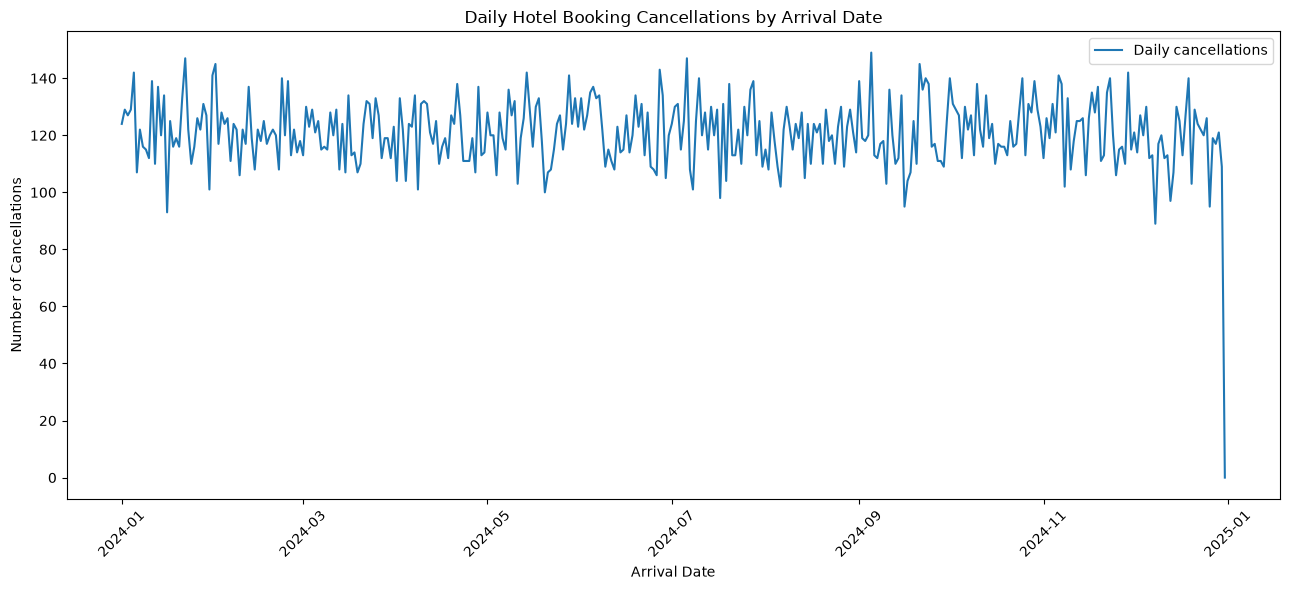

STEP 6 — DAILY CANCELLATION TREND VISUALIZATION
Chart saved to: C:\Users\admin\OneDrive\Desktop\Activity-2\output\time_series_results\step_06_daily_cancellations_chart.png

STEP 6 COMPLETED SUCCESSFULLY


In [72]:
# ============================================================
# STEP 6 — DAILY CANCELLATION TREND VISUALIZATION
# ============================================================

import os
import pandas as pd
import matplotlib.pyplot as plt

folder = os.path.join("output", "time_series_results")
input_file = os.path.join(
    folder, "step_04_daily_cancellation_trends.csv"
)

daily = pd.read_csv(input_file, parse_dates=["arrival_date"])

plt.figure(figsize=(13, 6))
plt.plot(
    daily["arrival_date"],
    daily["Cancellations"],
    label="Daily cancellations"
)
plt.title("Daily Hotel Booking Cancellations by Arrival Date")
plt.xlabel("Arrival Date")
plt.ylabel("Number of Cancellations")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()

chart_file = os.path.join(
    folder, "step_06_daily_cancellations_chart.png"
)
plt.savefig(chart_file, dpi=150, bbox_inches="tight")
plt.show()

print("=" * 70)
print("STEP 6 — DAILY CANCELLATION TREND VISUALIZATION")
print("=" * 70)
print("Chart saved to:", os.path.abspath(chart_file))
print("\nSTEP 6 COMPLETED SUCCESSFULLY")

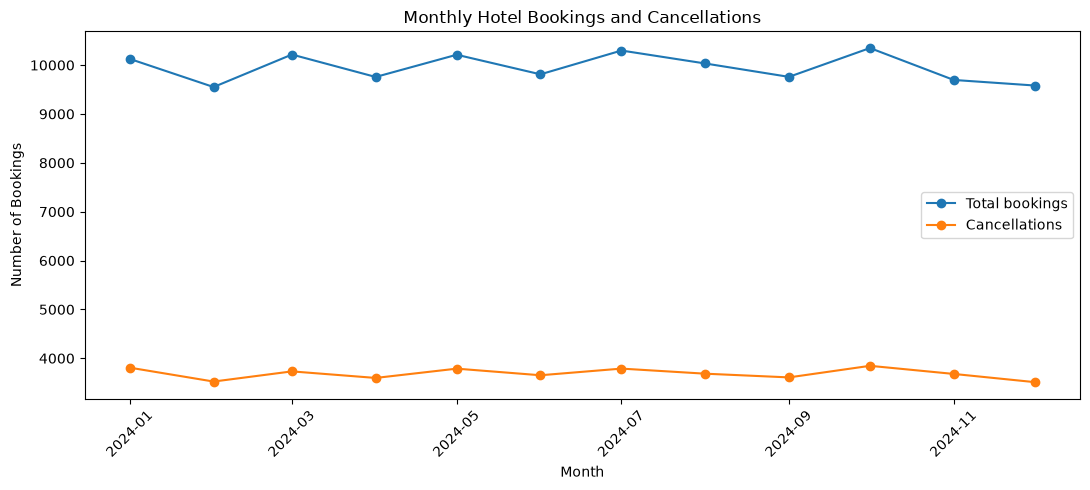

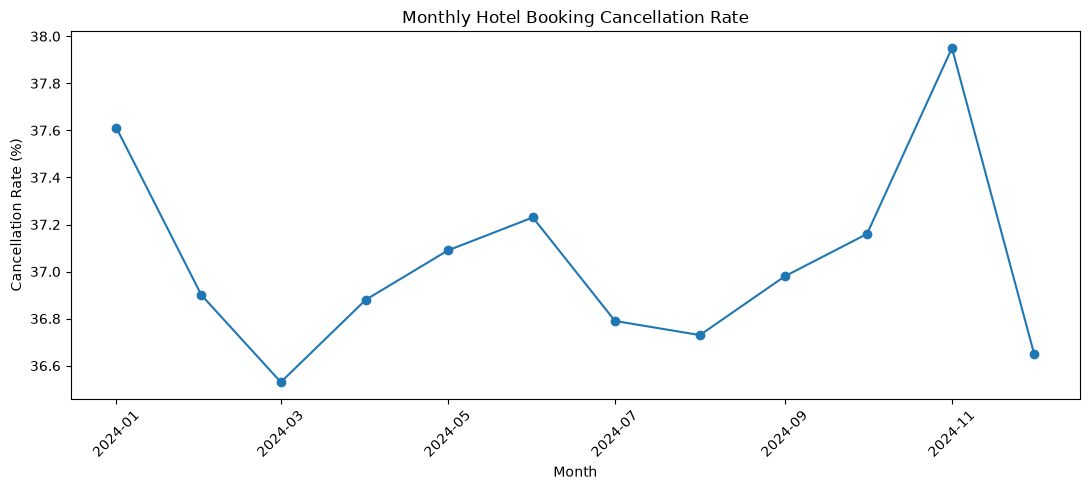

STEP 7 — MONTHLY TREND VISUALIZATION
Volume chart saved to: C:\Users\admin\OneDrive\Desktop\Activity-2\output\time_series_results\step_07_monthly_volume_chart.png
Rate chart saved to: C:\Users\admin\OneDrive\Desktop\Activity-2\output\time_series_results\step_07_monthly_cancellation_rate_chart.png

STEP 7 COMPLETED SUCCESSFULLY


In [73]:
# ============================================================
# STEP 7 — MONTHLY TREND VISUALIZATION
# ============================================================

import os
import pandas as pd
import matplotlib.pyplot as plt

folder = os.path.join("output", "time_series_results")
input_file = os.path.join(
    folder, "step_05_monthly_cancellation_trends.csv"
)

monthly = pd.read_csv(input_file, parse_dates=["Month_Start"])

plt.figure(figsize=(11, 5))
plt.plot(
    monthly["Month_Start"],
    monthly["Total_Bookings"],
    marker="o",
    label="Total bookings"
)
plt.plot(
    monthly["Month_Start"],
    monthly["Cancellations"],
    marker="o",
    label="Cancellations"
)
plt.title("Monthly Hotel Bookings and Cancellations")
plt.xlabel("Month")
plt.ylabel("Number of Bookings")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()

volume_file = os.path.join(
    folder, "step_07_monthly_volume_chart.png"
)
plt.savefig(volume_file, dpi=150, bbox_inches="tight")
plt.show()

plt.figure(figsize=(11, 5))
plt.plot(
    monthly["Month_Start"],
    monthly["Cancellation_Rate_Percent"],
    marker="o"
)
plt.title("Monthly Hotel Booking Cancellation Rate")
plt.xlabel("Month")
plt.ylabel("Cancellation Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()

rate_file = os.path.join(
    folder, "step_07_monthly_cancellation_rate_chart.png"
)
plt.savefig(rate_file, dpi=150, bbox_inches="tight")
plt.show()

print("=" * 70)
print("STEP 7 — MONTHLY TREND VISUALIZATION")
print("=" * 70)
print("Volume chart saved to:", os.path.abspath(volume_file))
print("Rate chart saved to:", os.path.abspath(rate_file))
print("\nSTEP 7 COMPLETED SUCCESSFULLY")

STEP 8 — CANCELLATION RATE BY HOTEL TYPE
  Hotel_Type  Total_Bookings  Cancellations  Cancellation_Rate_Percent
  City Hotel           79330          33102                      41.73
Resort Hotel           40060          11122                      27.76

Saved to: C:\Users\admin\OneDrive\Desktop\Activity-2\output\time_series_results\step_08_hotel_type_cancellation_summary.csv


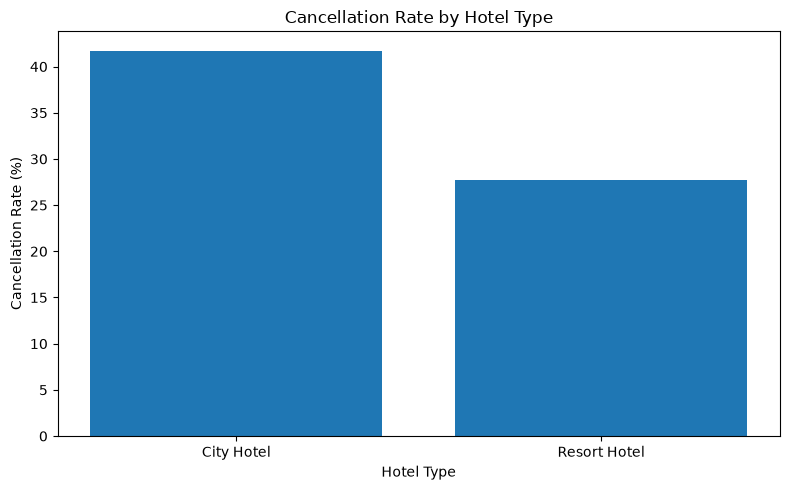

Chart saved to: C:\Users\admin\OneDrive\Desktop\Activity-2\output\time_series_results\step_08_hotel_type_cancellation_chart.png

STEP 8 COMPLETED SUCCESSFULLY


In [74]:
# ============================================================
# STEP 8 — CANCELLATION RATE BY HOTEL TYPE
# ============================================================

import os
import pandas as pd
import matplotlib.pyplot as plt

folder = os.path.join("output", "time_series_results")
input_file = os.path.join(
    folder, "step_03_time_series_prepared_data.csv"
)

df = pd.read_csv(input_file, low_memory=False)

df["Hotel_Type"] = (
    df["hotel"].astype(str)
    .str.extract(r"(?i)^\s*(Resort Hotel|City Hotel)", expand=False)
)

df["Hotel_Type"] = df["Hotel_Type"].str.title()

hotel_summary = (
    df.groupby("Hotel_Type")
    .agg(
        Total_Bookings=("is_canceled", "size"),
        Cancellations=("is_canceled", "sum")
    )
    .reset_index()
)

hotel_summary["Cancellation_Rate_Percent"] = (
    hotel_summary["Cancellations"]
    / hotel_summary["Total_Bookings"] * 100
).round(2)

output_file = os.path.join(
    folder, "step_08_hotel_type_cancellation_summary.csv"
)
hotel_summary.to_csv(output_file, index=False)

print("=" * 70)
print("STEP 8 — CANCELLATION RATE BY HOTEL TYPE")
print("=" * 70)
print(hotel_summary.to_string(index=False))
print("\nSaved to:", os.path.abspath(output_file))

plt.figure(figsize=(8, 5))
plt.bar(
    hotel_summary["Hotel_Type"].fillna("Other"),
    hotel_summary["Cancellation_Rate_Percent"]
)
plt.title("Cancellation Rate by Hotel Type")
plt.xlabel("Hotel Type")
plt.ylabel("Cancellation Rate (%)")
plt.tight_layout()

chart_file = os.path.join(
    folder, "step_08_hotel_type_cancellation_chart.png"
)
plt.savefig(chart_file, dpi=150, bbox_inches="tight")
plt.show()

print("Chart saved to:", os.path.abspath(chart_file))
print("\nSTEP 8 COMPLETED SUCCESSFULLY")

STEP 9 — CANCELLATION PATTERNS BY WEEKDAY
  Weekday  Total_Bookings  Cancellations  Cancellation_Rate_Percent
   Monday           17221           6343                      36.83
  Tuesday           16959           6269                      36.97
Wednesday           16997           6254                      36.79
 Thursday           17127           6412                      37.44
   Friday           16901           6234                      36.89
 Saturday           17128           6297                      36.76
   Sunday           17057           6415                      37.61

Saved to: C:\Users\admin\OneDrive\Desktop\Activity-2\output\time_series_results\step_09_weekday_cancellation_summary.csv


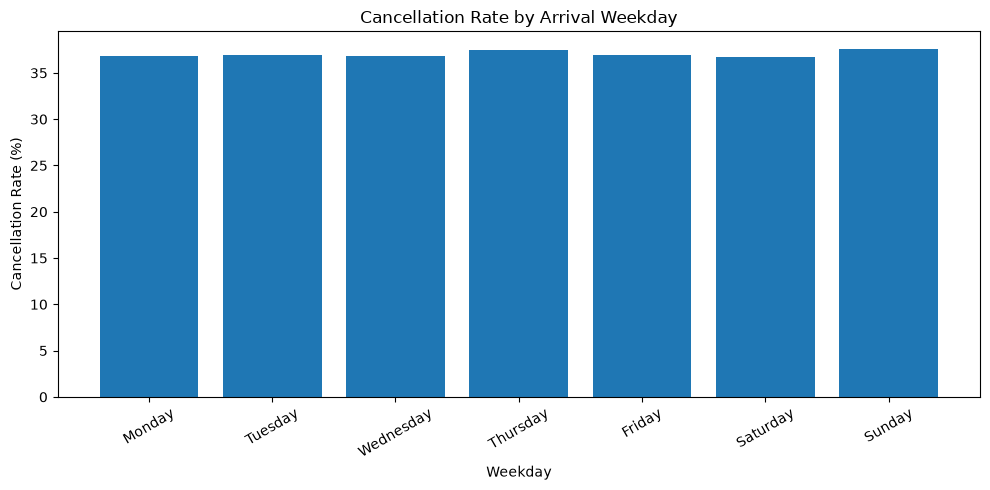

Chart saved to: C:\Users\admin\OneDrive\Desktop\Activity-2\output\time_series_results\step_09_weekday_cancellation_chart.png

STEP 9 COMPLETED SUCCESSFULLY


In [75]:
# ============================================================
# STEP 9 — CANCELLATION PATTERNS BY WEEKDAY
# ============================================================

import os
import pandas as pd
import matplotlib.pyplot as plt

folder = os.path.join("output", "time_series_results")
input_file = os.path.join(
    folder, "step_03_time_series_prepared_data.csv"
)

df = pd.read_csv(input_file, parse_dates=["arrival_date"])

df["Weekday"] = df["arrival_date"].dt.day_name()

weekday_order = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]

weekday_summary = (
    df.groupby("Weekday")
    .agg(
        Total_Bookings=("is_canceled", "size"),
        Cancellations=("is_canceled", "sum")
    )
    .reindex(weekday_order)
    .reset_index()
)

weekday_summary["Cancellation_Rate_Percent"] = (
    weekday_summary["Cancellations"]
    / weekday_summary["Total_Bookings"] * 100
).round(2)

output_file = os.path.join(
    folder, "step_09_weekday_cancellation_summary.csv"
)
weekday_summary.to_csv(output_file, index=False)

print("=" * 70)
print("STEP 9 — CANCELLATION PATTERNS BY WEEKDAY")
print("=" * 70)
print(weekday_summary.to_string(index=False))
print("\nSaved to:", os.path.abspath(output_file))

plt.figure(figsize=(10, 5))
plt.bar(
    weekday_summary["Weekday"],
    weekday_summary["Cancellation_Rate_Percent"]
)
plt.title("Cancellation Rate by Arrival Weekday")
plt.xlabel("Weekday")
plt.ylabel("Cancellation Rate (%)")
plt.xticks(rotation=30)
plt.tight_layout()

chart_file = os.path.join(
    folder, "step_09_weekday_cancellation_chart.png"
)
plt.savefig(chart_file, dpi=150, bbox_inches="tight")
plt.show()

print("Chart saved to:", os.path.abspath(chart_file))
print("\nSTEP 9 COMPLETED SUCCESSFULLY")

STEP 10 — MONTH-OF-YEAR CANCELLATION PATTERNS
 Month_Number Month_Name  Total_Bookings  Cancellations  Cancellation_Rate_Percent
            1    January           10126           3808                      37.61
            2   February            9551           3524                      36.90
            3      March           10216           3732                      36.53
            4      April            9757           3598                      36.88
            5        May           10212           3788                      37.09
            6       June            9811           3653                      37.23
            7       July           10298           3789                      36.79
            8     August           10033           3685                      36.73
            9  September            9759           3609                      36.98
           10    October           10349           3846                      37.16
           11   November            9696 

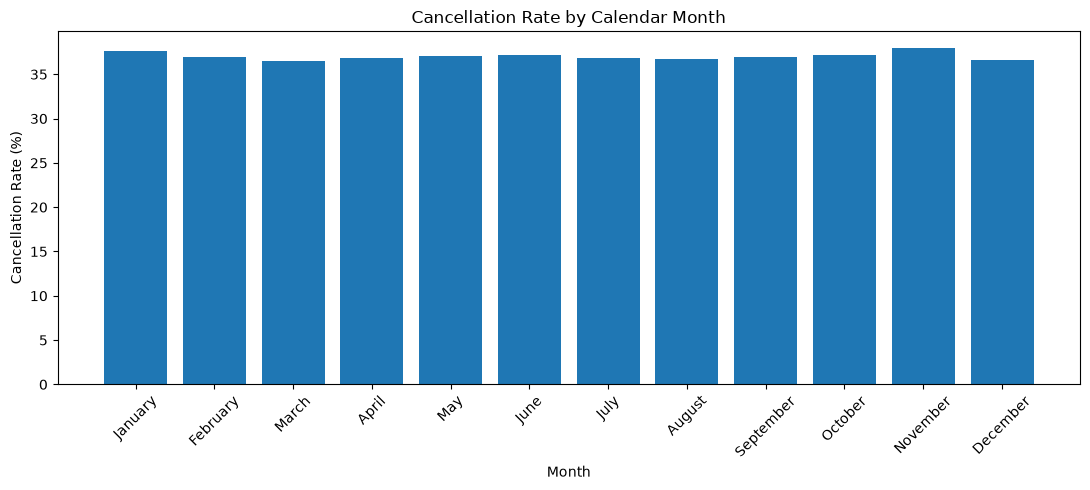

Chart saved to: C:\Users\admin\OneDrive\Desktop\Activity-2\output\time_series_results\step_10_month_of_year_cancellation_chart.png

STEP 10 COMPLETED SUCCESSFULLY


In [76]:
# ============================================================
# STEP 10 — MONTH-OF-YEAR CANCELLATION PATTERNS
# ============================================================

import os
import pandas as pd
import matplotlib.pyplot as plt

folder = os.path.join("output", "time_series_results")
input_file = os.path.join(
    folder, "step_03_time_series_prepared_data.csv"
)

df = pd.read_csv(input_file, parse_dates=["arrival_date"])

df["Month_Number"] = df["arrival_date"].dt.month
df["Month_Name"] = df["arrival_date"].dt.month_name()

month_order = list(range(1, 13))

month_summary = (
    df.groupby(["Month_Number", "Month_Name"])
    .agg(
        Total_Bookings=("is_canceled", "size"),
        Cancellations=("is_canceled", "sum")
    )
    .reset_index()
    .sort_values("Month_Number")
)

month_summary["Cancellation_Rate_Percent"] = (
    month_summary["Cancellations"]
    / month_summary["Total_Bookings"] * 100
).round(2)

output_file = os.path.join(
    folder, "step_10_month_of_year_cancellation_summary.csv"
)
month_summary.to_csv(output_file, index=False)

print("=" * 70)
print("STEP 10 — MONTH-OF-YEAR CANCELLATION PATTERNS")
print("=" * 70)
print(month_summary.to_string(index=False))
print("\nDistinct years in dataset:",
      df["arrival_date"].dt.year.nunique())
print("Years:", sorted(df["arrival_date"].dt.year.unique()))
print("\nSaved to:", os.path.abspath(output_file))

plt.figure(figsize=(11, 5))
plt.bar(
    month_summary["Month_Name"],
    month_summary["Cancellation_Rate_Percent"]
)
plt.title("Cancellation Rate by Calendar Month")
plt.xlabel("Month")
plt.ylabel("Cancellation Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()

chart_file = os.path.join(
    folder, "step_10_month_of_year_cancellation_chart.png"
)
plt.savefig(chart_file, dpi=150, bbox_inches="tight")
plt.show()

print("Chart saved to:", os.path.abspath(chart_file))
print("\nSTEP 10 COMPLETED SUCCESSFULLY")

STEP 11 — SEVEN-DAY MOVING AVERAGE ANALYSIS
Daily records: 366

Latest 10 dates:
              Total_Bookings  Cancellations  Not_Canceled  Cancellation_Rate_Percent  Cancellation_Rate_7Day_MA  Cancellations_7Day_MA
arrival_date                                                                                                                          
2024-12-22               333            124           209                      37.24                      37.80                 123.00
2024-12-23               299            122           177                      40.80                      38.20                 122.57
2024-12-24               333            120           213                      36.04                      38.34                 123.57
2024-12-25               310            126           184                      40.65                      38.17                 123.43
2024-12-26               293             95           198                      32.42                      37.

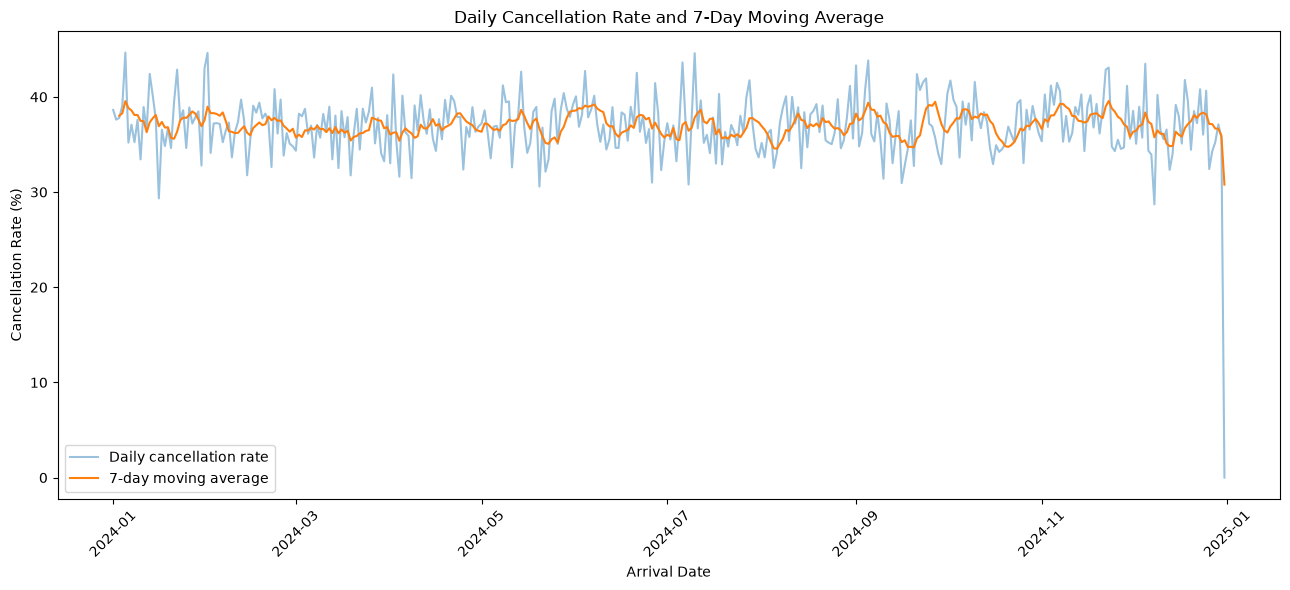

Chart saved to: C:\Users\admin\OneDrive\Desktop\Activity-2\output\time_series_results\step_11_cancellation_moving_average_chart.png

STEP 11 COMPLETED SUCCESSFULLY


In [77]:
# ============================================================
# STEP 11 — SEVEN-DAY MOVING AVERAGE ANALYSIS
# ============================================================

import os
import pandas as pd
import matplotlib.pyplot as plt

folder = os.path.join("output", "time_series_results")
input_file = os.path.join(
    folder, "step_04_daily_cancellation_trends.csv"
)

daily = pd.read_csv(input_file, parse_dates=["arrival_date"])
daily = daily.set_index("arrival_date").sort_index()

# Fill missing calendar dates with zero bookings
calendar = pd.date_range(
    daily.index.min(), daily.index.max(), freq="D"
)
daily = daily.reindex(calendar)
daily.index.name = "arrival_date"

for column in ["Total_Bookings", "Cancellations", "Not_Canceled"]:
    daily[column] = daily[column].fillna(0)

daily["Cancellation_Rate_Percent"] = (
    daily["Cancellations"]
    .div(daily["Total_Bookings"].replace(0, float("nan")))
    * 100
)

daily["Cancellation_Rate_7Day_MA"] = (
    daily["Cancellation_Rate_Percent"]
    .rolling(window=7, min_periods=3)
    .mean()
)

daily["Cancellations_7Day_MA"] = (
    daily["Cancellations"]
    .rolling(window=7, min_periods=3)
    .mean()
)

output_file = os.path.join(
    folder, "step_11_daily_moving_average.csv"
)
daily.reset_index().to_csv(output_file, index=False)

print("=" * 70)
print("STEP 11 — SEVEN-DAY MOVING AVERAGE ANALYSIS")
print("=" * 70)
print("Daily records:", len(daily))
print("\nLatest 10 dates:")
print(daily.tail(10).round(2).to_string())
print("\nSaved to:", os.path.abspath(output_file))

plt.figure(figsize=(13, 6))
plt.plot(
    daily.index,
    daily["Cancellation_Rate_Percent"],
    alpha=0.45,
    label="Daily cancellation rate"
)
plt.plot(
    daily.index,
    daily["Cancellation_Rate_7Day_MA"],
    label="7-day moving average"
)
plt.title("Daily Cancellation Rate and 7-Day Moving Average")
plt.xlabel("Arrival Date")
plt.ylabel("Cancellation Rate (%)")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()

chart_file = os.path.join(
    folder, "step_11_cancellation_moving_average_chart.png"
)
plt.savefig(chart_file, dpi=150, bbox_inches="tight")
plt.show()

print("Chart saved to:", os.path.abspath(chart_file))
print("\nSTEP 11 COMPLETED SUCCESSFULLY")

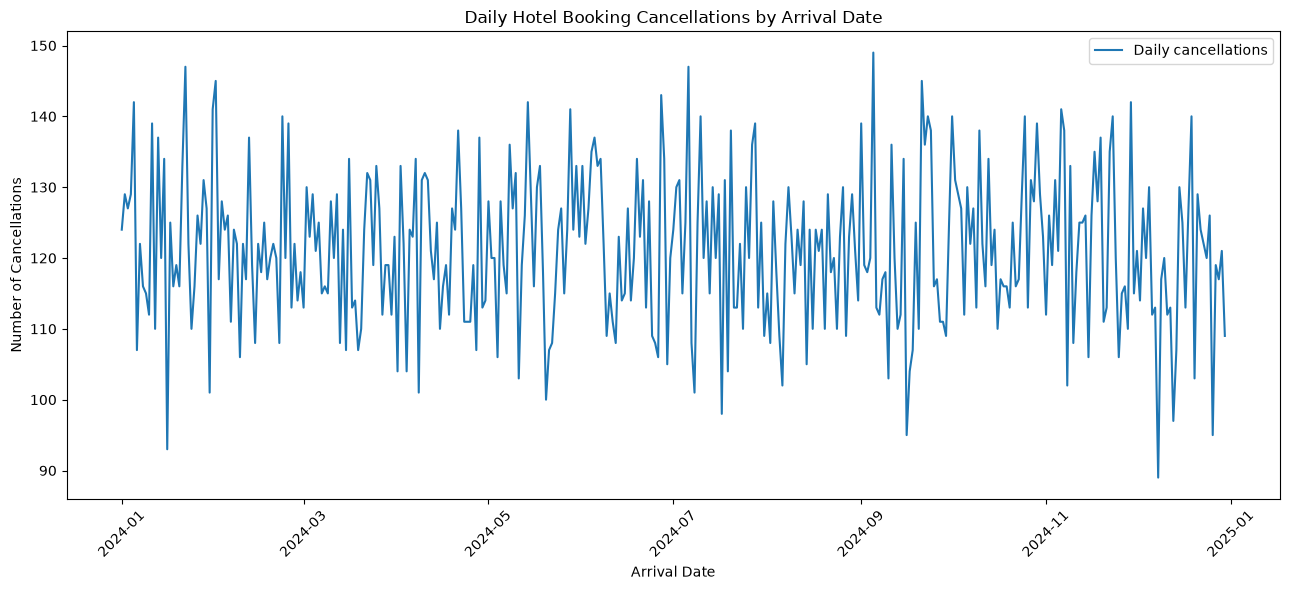

STEP 12 — DAILY TREND CHART QUALITY IMPROVEMENT
                          Item                                                                                                            Result
                          Step                                                                   Step 12 — Daily Trend Chart Quality Improvement
                     Last_Date                                                                                                        2024-12-31
         Bookings_On_Last_Date                                                                                                                 2
       Dates_In_Original_Table                                                                                                               366
        Dates_In_Revised_Chart                                                                                                               365
Final_Date_Excluded_From_Chart                                                    

In [78]:
# ============================================================
# STEP 12 — DAILY TREND CHART QUALITY IMPROVEMENT
# ============================================================

import os
import pandas as pd
import matplotlib.pyplot as plt
from datetime import datetime

folder = os.path.join("output", "time_series_results")

input_file = os.path.join(
    folder, "step_04_daily_cancellation_trends.csv"
)

daily = pd.read_csv(
    input_file, parse_dates=["arrival_date"]
).sort_values("arrival_date")

# Identify the final date and its booking count
last_date = daily["arrival_date"].max()
last_day_bookings = int(
    daily.loc[
        daily["arrival_date"] == last_date,
        "Total_Bookings"
    ].sum()
)

# Exclude the final date from the chart if it has fewer
# than 50 bookings. This does not delete it from the dataset.
chart_data = daily.copy()

if last_day_bookings < 50:
    chart_data = daily[daily["arrival_date"] < last_date].copy()

# Save revised chart
plt.figure(figsize=(13, 6))
plt.plot(
    chart_data["arrival_date"],
    chart_data["Cancellations"],
    label="Daily cancellations"
)
plt.title("Daily Hotel Booking Cancellations by Arrival Date")
plt.xlabel("Arrival Date")
plt.ylabel("Number of Cancellations")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()

chart_file = os.path.join(
    folder, "step_12_daily_cancellations_clean_chart.png"
)
plt.savefig(chart_file, dpi=150, bbox_inches="tight")
plt.show()

# Save quality-check summary
summary = {
    "Step": "Step 12 — Daily Trend Chart Quality Improvement",
    "Last_Date": str(last_date.date()),
    "Bookings_On_Last_Date": last_day_bookings,
    "Dates_In_Original_Table": len(daily),
    "Dates_In_Revised_Chart": len(chart_data),
    "Final_Date_Excluded_From_Chart": (
        "Yes" if len(chart_data) < len(daily) else "No"
    ),
    "Original_Data_Modified": "No",
    "Chart_File": os.path.abspath(chart_file),
    "Date_Analyzed": datetime.now().strftime("%Y-%m-%d %H:%M:%S")
}

summary_df = pd.DataFrame(
    list(summary.items()),
    columns=["Item", "Result"]
)

output_file = os.path.join(
    folder, "step_12_daily_chart_quality_summary.csv"
)
summary_df.to_csv(output_file, index=False)

print("=" * 70)
print("STEP 12 — DAILY TREND CHART QUALITY IMPROVEMENT")
print("=" * 70)
print(summary_df.to_string(index=False))
print("\nSummary saved to:", os.path.abspath(output_file))
print("\nSTEP 12 COMPLETED SUCCESSFULLY")

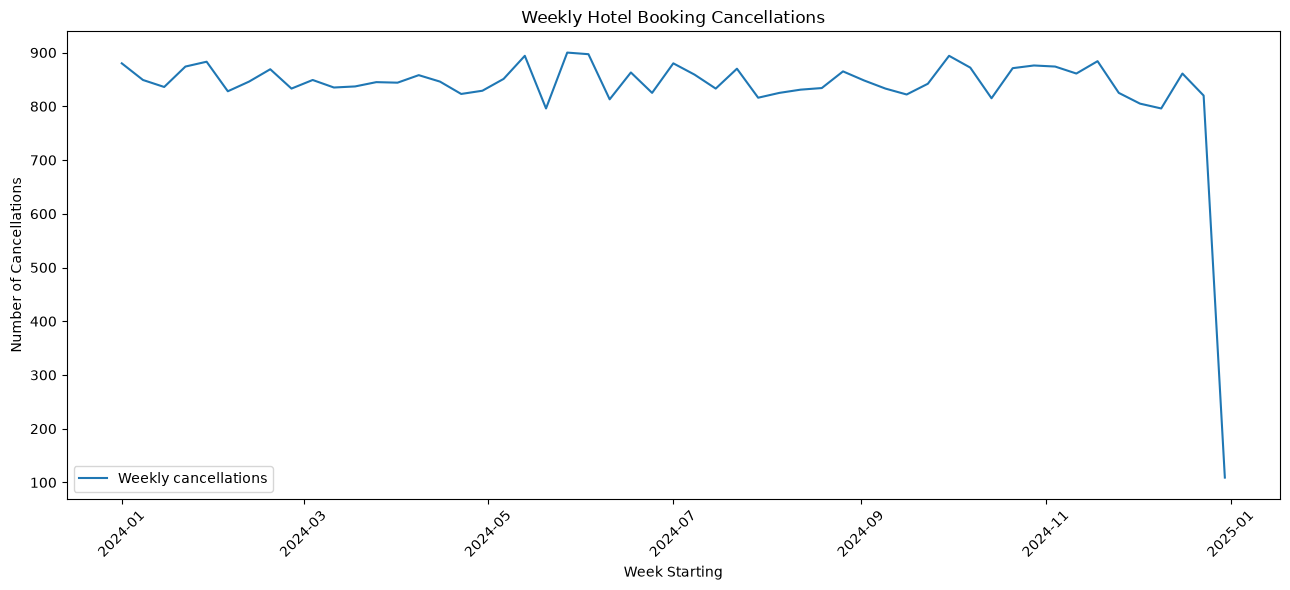

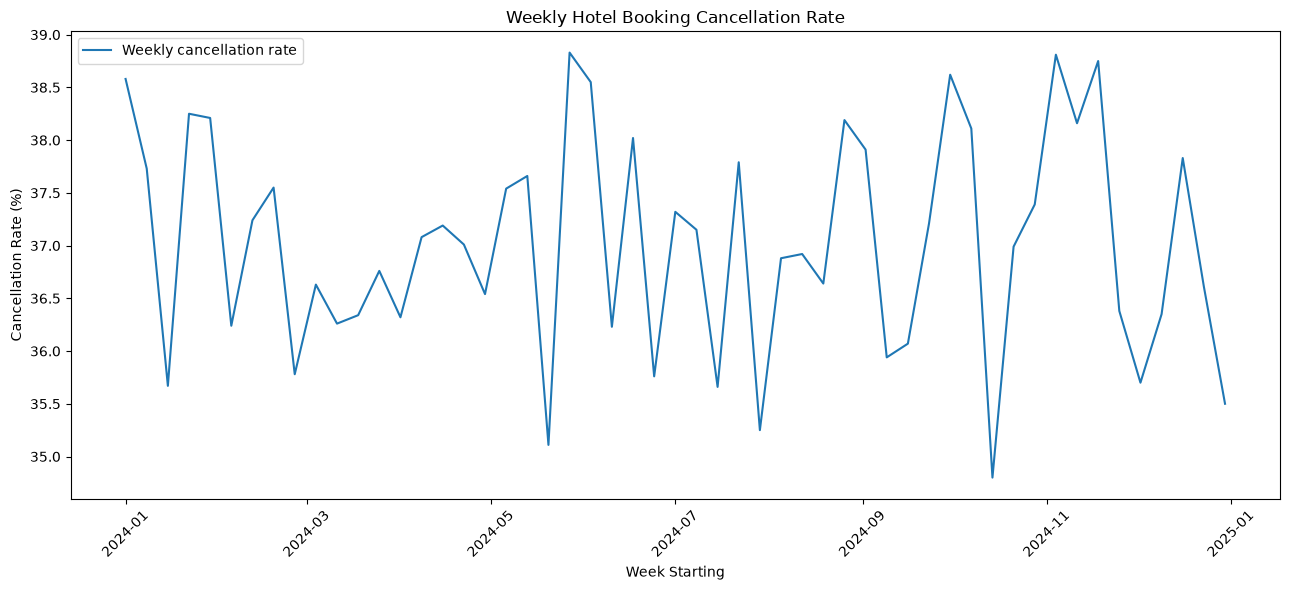

STEP 13 — WEEKLY BOOKING AND CANCELLATION ANALYSIS
Weeks analyzed: 53

First 10 weeks:
Week_Start  Total_Bookings  Cancellations  Not_Canceled  Cancellation_Rate_Percent
2024-01-01            2281            880          1401                      38.58
2024-01-08            2250            849          1401                      37.73
2024-01-15            2344            836          1508                      35.67
2024-01-22            2285            874          1411                      38.25
2024-01-29            2311            883          1428                      38.21
2024-02-05            2285            828          1457                      36.24
2024-02-12            2272            846          1426                      37.24
2024-02-19            2314            869          1445                      37.55
2024-02-26            2328            833          1495                      35.78
2024-03-04            2318            849          1469                      36.63


In [79]:
# ============================================================
# STEP 13 — WEEKLY BOOKING AND CANCELLATION ANALYSIS
# ============================================================

import os
import pandas as pd
import matplotlib.pyplot as plt
from datetime import datetime

folder = os.path.join("output", "time_series_results")
input_file = os.path.join(
    folder, "step_03_time_series_prepared_data.csv"
)

# Load prepared data
df = pd.read_csv(input_file, parse_dates=["arrival_date"])

# Create weekly periods starting Monday
df["Week_Start"] = (
    df["arrival_date"]
    .dt.to_period("W-SUN")
    .dt.start_time
)

# Aggregate bookings and cancellations
weekly = (
    df.groupby("Week_Start")
    .agg(
        Total_Bookings=("is_canceled", "size"),
        Cancellations=("is_canceled", "sum")
    )
    .reset_index()
    .sort_values("Week_Start")
)

weekly["Not_Canceled"] = (
    weekly["Total_Bookings"] - weekly["Cancellations"]
)

weekly["Cancellation_Rate_Percent"] = (
    weekly["Cancellations"]
    / weekly["Total_Bookings"] * 100
).round(2)

# Save weekly results
output_file = os.path.join(
    folder, "step_13_weekly_cancellation_analysis.csv"
)
weekly.to_csv(output_file, index=False)

# Create weekly cancellation chart
plt.figure(figsize=(13, 6))
plt.plot(
    weekly["Week_Start"],
    weekly["Cancellations"],
    label="Weekly cancellations"
)
plt.title("Weekly Hotel Booking Cancellations")
plt.xlabel("Week Starting")
plt.ylabel("Number of Cancellations")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()

chart_file = os.path.join(
    folder, "step_13_weekly_cancellations_chart.png"
)
plt.savefig(chart_file, dpi=150, bbox_inches="tight")
plt.show()

# Create weekly cancellation-rate chart
plt.figure(figsize=(13, 6))
plt.plot(
    weekly["Week_Start"],
    weekly["Cancellation_Rate_Percent"],
    label="Weekly cancellation rate"
)
plt.title("Weekly Hotel Booking Cancellation Rate")
plt.xlabel("Week Starting")
plt.ylabel("Cancellation Rate (%)")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()

rate_chart_file = os.path.join(
    folder, "step_13_weekly_cancellation_rate_chart.png"
)
plt.savefig(rate_chart_file, dpi=150, bbox_inches="tight")
plt.show()

print("=" * 70)
print("STEP 13 — WEEKLY BOOKING AND CANCELLATION ANALYSIS")
print("=" * 70)

print("Weeks analyzed:", len(weekly))
print("\nFirst 10 weeks:")
print(weekly.head(10).to_string(index=False))

print("\nOverall weekly-table totals:")
print("Bookings:", int(weekly["Total_Bookings"].sum()))
print("Cancellations:", int(weekly["Cancellations"].sum()))

print("\nWeekly data saved to:")
print(os.path.abspath(output_file))

print("\nCancellation chart saved to:")
print(os.path.abspath(chart_file))

print("\nRate chart saved to:")
print(os.path.abspath(rate_chart_file))

print("\nSTEP 13 COMPLETED SUCCESSFULLY")

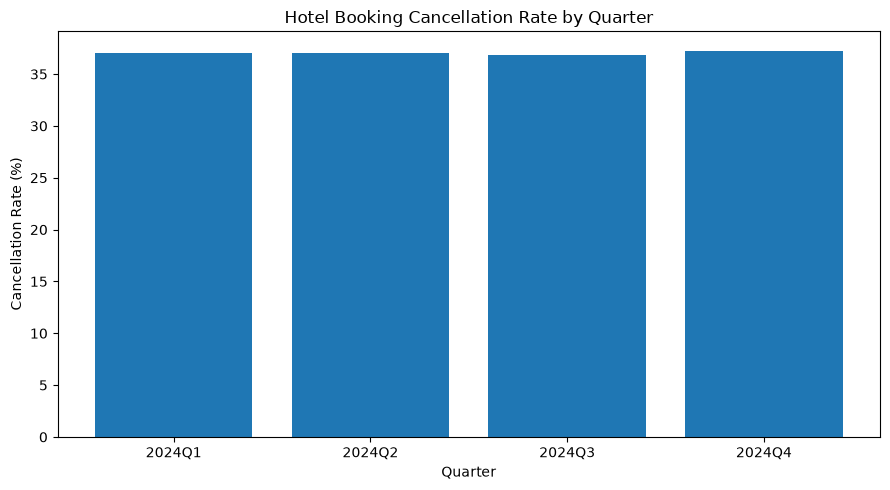

STEP 14 - QUARTERLY BOOKING AND CANCELLATION ANALYSIS
Bookings on original final date: 2

Quarterly results:
Quarter  Total_Bookings  Cancellations  Not_Canceled  Cancellation_Rate_Percent
 2024Q1           29893          11064         18829                      37.01
 2024Q2           29780          11039         18741                      37.07
 2024Q3           30090          11083         19007                      36.83
 2024Q4           29625          11038         18587                      37.26

CSV saved to: C:\Users\admin\OneDrive\Desktop\Activity-2\output\time_series_results\step_14_quarterly_cancellation_analysis.csv
Chart saved to: C:\Users\admin\OneDrive\Desktop\Activity-2\output\time_series_results\step_14_quarterly_cancellation_chart.png

STEP 14 COMPLETED SUCCESSFULLY


In [80]:
# ============================================================
# STEP 14 - QUARTERLY BOOKING AND CANCELLATION ANALYSIS
# ============================================================

import os
import pandas as pd
import matplotlib.pyplot as plt

# Dataset path
dataset_path = r"C:\Users\admin\OneDrive\Desktop\Activity-2\output\preprocessing_results\hotel_bookings_cleaned.csv"

# Output folder
output_folder = r"C:\Users\admin\OneDrive\Desktop\Activity-2\output\time_series_results"
os.makedirs(output_folder, exist_ok=True)

# Load dataset
df = pd.read_csv(dataset_path)

# Prepare dates and cancellation labels
df["arrival_date"] = pd.to_datetime(df["arrival_date"], errors="coerce")
df["is_canceled"] = pd.to_numeric(df["is_canceled"], errors="coerce")

df = df.dropna(subset=["arrival_date", "is_canceled"])
df = df[df["is_canceled"].isin([0, 1])].copy()

# Exclude the partial final date from this analysis
last_date = df["arrival_date"].max()
bookings_on_last_date = (df["arrival_date"] == last_date).sum()

if bookings_on_last_date < 10:
    df = df[df["arrival_date"] < last_date].copy()

# Assign calendar quarters
df["Quarter"] = df["arrival_date"].dt.to_period("Q").astype(str)

# Aggregate bookings and cancellations
quarterly = df.groupby("Quarter").agg(
    Total_Bookings=("is_canceled", "size"),
    Cancellations=("is_canceled", "sum")
).reset_index()

quarterly["Not_Canceled"] = (
    quarterly["Total_Bookings"] - quarterly["Cancellations"]
)

quarterly["Cancellation_Rate_Percent"] = (
    quarterly["Cancellations"] / quarterly["Total_Bookings"] * 100
).round(2)

# Save summary
csv_path = os.path.join(
    output_folder, "step_14_quarterly_cancellation_analysis.csv"
)
quarterly.to_csv(csv_path, index=False)

# Plot quarterly cancellation rates
chart_path = os.path.join(
    output_folder, "step_14_quarterly_cancellation_chart.png"
)

plt.figure(figsize=(9, 5))
plt.bar(
    quarterly["Quarter"],
    quarterly["Cancellation_Rate_Percent"]
)
plt.title("Hotel Booking Cancellation Rate by Quarter")
plt.xlabel("Quarter")
plt.ylabel("Cancellation Rate (%)")
plt.tight_layout()
plt.savefig(chart_path, dpi=150)
plt.show()

print("=" * 65)
print("STEP 14 - QUARTERLY BOOKING AND CANCELLATION ANALYSIS")
print("=" * 65)
print("Bookings on original final date:", bookings_on_last_date)
print("\nQuarterly results:")
print(quarterly.to_string(index=False))
print("\nCSV saved to:", os.path.abspath(csv_path))
print("Chart saved to:", os.path.abspath(chart_path))
print("\nSTEP 14 COMPLETED SUCCESSFULLY")

In [81]:

%pip install statsmodels


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: C:\Users\admin\AppData\Local\Programs\Python\Python314\python.exe -m pip install --upgrade pip


C:\Users\admin\AppData\Local\Temp\ipykernel_10544\1680262944.py:25: FutureWarning: `extrapolate_trend='freq'` is deprecated and will be removed in 0.16, use `extrapolate_trend='period'` instead.
  decomposition = seasonal_decompose(


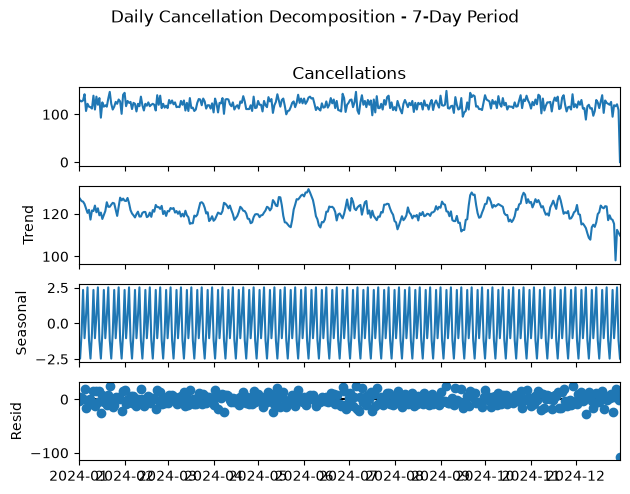

STEP 15 - TIME-SERIES TREND DECOMPOSITION
Daily observations: 366
Seasonal period: 7 days

First five rows:
              Observed       Trend  Weekly_Seasonal   Residual
arrival_date                                                  
2024-01-01       124.0  127.938776        -1.176963  -2.761813
2024-01-02       129.0  126.948980        -2.467683   4.518703
2024-01-03       127.0  125.959184        -0.704391   1.745207
2024-01-04       129.0  125.714286         2.341527   0.944187
2024-01-05       142.0  124.571429        -1.040341  18.468912

Components saved to: C:\Users\admin\OneDrive\Desktop\Activity-2\output\time_series_results\step_15_decomposition_components.csv
Chart saved to: C:\Users\admin\OneDrive\Desktop\Activity-2\output\time_series_results\step_15_trend_decomposition.png

STEP 15 COMPLETED SUCCESSFULLY


In [82]:
# ============================================================
# STEP 15 - TIME-SERIES TREND DECOMPOSITION
# ============================================================

import os
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose

folder = r"C:\Users\admin\OneDrive\Desktop\Activity-2\output\time_series_results"
os.makedirs(folder, exist_ok=True)

input_file = os.path.join(folder, "step_04_daily_cancellation_trends.csv")
daily = pd.read_csv(input_file)

daily["arrival_date"] = pd.to_datetime(daily["arrival_date"], errors="coerce")
daily["Cancellations"] = pd.to_numeric(daily["Cancellations"], errors="coerce")
daily = daily.dropna(subset=["arrival_date", "Cancellations"])
daily = daily.sort_values("arrival_date").drop_duplicates("arrival_date")
daily = daily.set_index("arrival_date").asfreq("D")

# Interpolate missing dates for the decomposition only
series = daily["Cancellations"].interpolate(limit_direction="both")

decomposition = seasonal_decompose(
    series, model="additive", period=7, extrapolate_trend="freq"
)

components = pd.DataFrame({
    "Observed": decomposition.observed,
    "Trend": decomposition.trend,
    "Weekly_Seasonal": decomposition.seasonal,
    "Residual": decomposition.resid
})

output_file = os.path.join(folder, "step_15_decomposition_components.csv")
chart_file = os.path.join(folder, "step_15_trend_decomposition.png")

components.to_csv(output_file)

decomposition.plot()
plt.suptitle("Daily Cancellation Decomposition - 7-Day Period", y=1.02)
plt.tight_layout()
plt.savefig(chart_file, dpi=150, bbox_inches="tight")
plt.show()

print("=" * 65)
print("STEP 15 - TIME-SERIES TREND DECOMPOSITION")
print("=" * 65)
print("Daily observations:", len(series))
print("Seasonal period: 7 days")
print("\nFirst five rows:")
print(components.head().to_string())
print("\nComponents saved to:", os.path.abspath(output_file))
print("Chart saved to:", os.path.abspath(chart_file))
print("\nSTEP 15 COMPLETED SUCCESSFULLY")

In [83]:
# ============================================================
# STEP 16 - STATIONARITY TEST
# ============================================================

import os
import pandas as pd
from statsmodels.tsa.stattools import adfuller

folder = r"C:\Users\admin\OneDrive\Desktop\Activity-2\output\time_series_results"

input_file = os.path.join(folder, "step_04_daily_cancellation_trends.csv")
daily = pd.read_csv(input_file)

series = pd.to_numeric(daily["Cancellations"], errors="coerce").dropna()

result = adfuller(series)

summary = pd.DataFrame([{
    "ADF_Statistic": result[0],
    "P_Value": result[1],
    "Lags_Used": result[2],
    "Observations": result[3],
    "Critical_Value_1_Percent": result[4]["1%"],
    "Critical_Value_5_Percent": result[4]["5%"],
    "Critical_Value_10_Percent": result[4]["10%"],
    "Interpretation": (
        "Evidence against a unit root at 5% significance"
        if result[1] < 0.05
        else "Insufficient evidence against a unit root at 5% significance"
    )
}])

output_file = os.path.join(folder, "step_16_stationarity_test.csv")
summary.to_csv(output_file, index=False)

print("=" * 65)
print("STEP 16 - STATIONARITY TEST")
print("=" * 65)
print(summary.to_string(index=False))
print("\nSaved to:", os.path.abspath(output_file))
print("\nSTEP 16 COMPLETED SUCCESSFULLY")

STEP 16 - STATIONARITY TEST
 ADF_Statistic      P_Value  Lags_Used  Observations  Critical_Value_1_Percent  Critical_Value_5_Percent  Critical_Value_10_Percent                                  Interpretation
    -16.147048 4.611415e-29          0           365                 -3.448394                 -2.869491                  -2.571006 Evidence against a unit root at 5% significance

Saved to: C:\Users\admin\OneDrive\Desktop\Activity-2\output\time_series_results\step_16_stationarity_test.csv

STEP 16 COMPLETED SUCCESSFULLY


C:\Users\admin\AppData\Local\Temp\ipykernel_10544\2119188349.py:16: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(series)


In [84]:
# ============================================================
# STEP 17 - FORECASTING DATASET PREPARATION
# ============================================================

import os
import pandas as pd

dataset_path = r"C:\Users\admin\OneDrive\Desktop\Activity-2\output\preprocessing_results\hotel_bookings_cleaned.csv"
folder = r"C:\Users\admin\OneDrive\Desktop\Activity-2\output\time_series_results"
os.makedirs(folder, exist_ok=True)

df = pd.read_csv(dataset_path)

df["arrival_date"] = pd.to_datetime(df["arrival_date"], errors="coerce")
df["is_canceled"] = pd.to_numeric(df["is_canceled"], errors="coerce")

df = df.dropna(subset=["arrival_date", "is_canceled"])
df = df[df["is_canceled"].isin([0, 1])].copy()

daily = df.groupby("arrival_date").agg(
    Total_Bookings=("is_canceled", "size"),
    Cancellations=("is_canceled", "sum")
).reset_index()

# Complete the calendar, retaining zero-booking dates as zero counts
daily = daily.set_index("arrival_date").asfreq("D")
daily[["Total_Bookings", "Cancellations"]] = (
    daily[["Total_Bookings", "Cancellations"]].fillna(0)
)
daily = daily.reset_index()

output_file = os.path.join(folder, "step_17_forecasting_dataset.csv")
daily.to_csv(output_file, index=False)

print("=" * 65)
print("STEP 17 - FORECASTING DATASET PREPARATION")
print("=" * 65)
print("Daily records:", len(daily))
print("Total bookings:", int(daily["Total_Bookings"].sum()))
print("Total cancellations:", int(daily["Cancellations"].sum()))
print("\nFirst five rows:")
print(daily.head().to_string(index=False))
print("\nSaved to:", os.path.abspath(output_file))
print("\nSTEP 17 COMPLETED SUCCESSFULLY")

STEP 17 - FORECASTING DATASET PREPARATION
Daily records: 366
Total bookings: 119390
Total cancellations: 44224

First five rows:
arrival_date  Total_Bookings  Cancellations
  2024-01-01             321            124
  2024-01-02             343            129
  2024-01-03             336            127
  2024-01-04             330            129
  2024-01-05             318            142

Saved to: C:\Users\admin\OneDrive\Desktop\Activity-2\output\time_series_results\step_17_forecasting_dataset.csv

STEP 17 COMPLETED SUCCESSFULLY


In [85]:
# ============================================================
# STEP 18 - LAG FEATURE CREATION
# ============================================================

import os
import pandas as pd

folder = r"C:\Users\admin\OneDrive\Desktop\Activity-2\output\time_series_results"

input_file = os.path.join(folder, "step_17_forecasting_dataset.csv")
daily = pd.read_csv(input_file)

daily["arrival_date"] = pd.to_datetime(daily["arrival_date"], errors="coerce")
daily = daily.sort_values("arrival_date").reset_index(drop=True)

daily["Lag_1"] = daily["Cancellations"].shift(1)
daily["Lag_7"] = daily["Cancellations"].shift(7)
daily["Lag_14"] = daily["Cancellations"].shift(14)

daily["Rolling_Mean_7"] = (
    daily["Cancellations"].shift(1).rolling(window=7).mean()
)

daily["Day_Of_Week"] = daily["arrival_date"].dt.dayofweek

features = daily.dropna().copy()

output_file = os.path.join(folder, "step_18_lag_features.csv")
features.to_csv(output_file, index=False)

print("=" * 65)
print("STEP 18 - LAG FEATURE CREATION")
print("=" * 65)
print("Rows before feature creation:", len(daily))
print("Rows after feature creation:", len(features))
print("\nCreated features:")
print("Lag_1, Lag_7, Lag_14, Rolling_Mean_7, Day_Of_Week")
print("\nFirst five rows:")
print(features.head().to_string(index=False))
print("\nSaved to:", os.path.abspath(output_file))
print("\nSTEP 18 COMPLETED SUCCESSFULLY")

STEP 18 - LAG FEATURE CREATION
Rows before feature creation: 366
Rows after feature creation: 352

Created features:
Lag_1, Lag_7, Lag_14, Rolling_Mean_7, Day_Of_Week

First five rows:
arrival_date  Total_Bookings  Cancellations  Lag_1  Lag_7  Lag_14  Rolling_Mean_7  Day_Of_Week
  2024-01-15             356            134  120.0  116.0   124.0      121.285714            0
  2024-01-16             317             93  134.0  115.0   129.0      123.857143            1
  2024-01-17             342            125   93.0  112.0   127.0      120.714286            2
  2024-01-18             333            116  125.0  139.0   129.0      122.571429            3
  2024-01-19             324            119  116.0  110.0   142.0      119.285714            4

Saved to: C:\Users\admin\OneDrive\Desktop\Activity-2\output\time_series_results\step_18_lag_features.csv

STEP 18 COMPLETED SUCCESSFULLY


In [86]:
# ============================================================
# STEP 19 - CHRONOLOGICAL TRAIN-TEST SPLIT
# ============================================================

import os
import pandas as pd

folder = r"C:\Users\admin\OneDrive\Desktop\Activity-2\output\time_series_results"

input_file = os.path.join(folder, "step_18_lag_features.csv")
data = pd.read_csv(input_file)

data["arrival_date"] = pd.to_datetime(data["arrival_date"], errors="coerce")
data = data.sort_values("arrival_date").reset_index(drop=True)

split_index = int(len(data) * 0.80)

train = data.iloc[:split_index].copy()
test = data.iloc[split_index:].copy()

train_file = os.path.join(folder, "step_19_train_data.csv")
test_file = os.path.join(folder, "step_19_test_data.csv")

train.to_csv(train_file, index=False)
test.to_csv(test_file, index=False)

print("=" * 65)
print("STEP 19 - CHRONOLOGICAL TRAIN-TEST SPLIT")
print("=" * 65)
print("Training rows:", len(train))
print("Testing rows:", len(test))
print("Training period:", train["arrival_date"].min(), "to", train["arrival_date"].max())
print("Testing period:", test["arrival_date"].min(), "to", test["arrival_date"].max())
print("\nTraining data saved to:", os.path.abspath(train_file))
print("Testing data saved to:", os.path.abspath(test_file))
print("\nSTEP 19 COMPLETED SUCCESSFULLY")

STEP 19 - CHRONOLOGICAL TRAIN-TEST SPLIT
Training rows: 281
Testing rows: 71
Training period: 2024-01-15 00:00:00 to 2024-10-21 00:00:00
Testing period: 2024-10-22 00:00:00 to 2024-12-31 00:00:00

Training data saved to: C:\Users\admin\OneDrive\Desktop\Activity-2\output\time_series_results\step_19_train_data.csv
Testing data saved to: C:\Users\admin\OneDrive\Desktop\Activity-2\output\time_series_results\step_19_test_data.csv

STEP 19 COMPLETED SUCCESSFULLY


In [87]:
# ============================================================
# STEP 20 - BASELINE FORECAST EVALUATION
# ============================================================

import os
import pandas as pd
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

folder = r"C:\Users\admin\OneDrive\Desktop\Activity-2\output\time_series_results"

input_file = os.path.join(folder, "step_18_lag_features.csv")
data = pd.read_csv(input_file)
data["arrival_date"] = pd.to_datetime(data["arrival_date"], errors="coerce")
data = data.sort_values("arrival_date").reset_index(drop=True)

split_index = int(len(data) * 0.80)
test = data.iloc[split_index:].copy()

actual = test["Cancellations"].to_numpy()
predicted = test["Rolling_Mean_7"].to_numpy()

mae = mean_absolute_error(actual, predicted)
rmse = np.sqrt(mean_squared_error(actual, predicted))

metrics = pd.DataFrame([{
    "Model": "Previous 7-Day Rolling Mean",
    "Test_Rows": len(test),
    "MAE": round(mae, 3),
    "RMSE": round(rmse, 3)
}])

output_file = os.path.join(folder, "step_20_baseline_metrics.csv")
metrics.to_csv(output_file, index=False)

print("=" * 65)
print("STEP 20 - BASELINE FORECAST EVALUATION")
print("=" * 65)
print(metrics.to_string(index=False))
print("\nSaved to:", os.path.abspath(output_file))
print("\nSTEP 20 COMPLETED SUCCESSFULLY")

STEP 20 - BASELINE FORECAST EVALUATION
                      Model  Test_Rows  MAE  RMSE
Previous 7-Day Rolling Mean         71 10.7  18.0

Saved to: C:\Users\admin\OneDrive\Desktop\Activity-2\output\time_series_results\step_20_baseline_metrics.csv

STEP 20 COMPLETED SUCCESSFULLY


In [88]:
# ============================================================
# STEP 21 - IMPROVED RANDOM FOREST FORECAST MODEL
# ============================================================

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

folder = r"C:\Users\admin\OneDrive\Desktop\Activity-2\output\time_series_results"
os.makedirs(folder, exist_ok=True)

# Use lag features created in Step 18
input_file = os.path.join(folder, "step_18_lag_features.csv")
data = pd.read_csv(input_file, parse_dates=["arrival_date"])
data = data.sort_values("arrival_date").reset_index(drop=True)

# Use only features available from previous days
feature_columns = ["Lag_1", "Lag_7", "Lag_14", "Rolling_Mean_7", "Day_Of_Week"]
target_column = "Cancellations"

data = data.dropna(subset=feature_columns + [target_column]).copy()

X = data[feature_columns]
y = data[target_column]

# Chronological split: first 80% for training, last 20% for testing
split_index = int(len(data) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]
y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

# Train model
model = RandomForestRegressor(
    n_estimators=300,
    max_depth=5,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)
predictions = model.predict(X_test)

# Evaluate honestly
mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))
r2 = r2_score(y_test, predictions)

metrics = pd.DataFrame([{
    "Model": "Improved Random Forest",
    "Test_Rows": len(y_test),
    "MAE": round(mae, 3),
    "RMSE": round(rmse, 3),
    "R2": round(r2, 3)
}])

metrics_file = os.path.join(folder, "step_21_random_forest_metrics.csv")
predictions_file = os.path.join(folder, "step_21_random_forest_predictions.csv")
model_file = os.path.join(folder, "step_21_cancellation_forecast_model.pkl")

metrics.to_csv(metrics_file, index=False)

prediction_results = pd.DataFrame({
    "arrival_date": data["arrival_date"].iloc[split_index:].values,
    "Actual_Cancellations": y_test.values,
    "Predicted_Cancellations": predictions.round(2)
})
prediction_results.to_csv(predictions_file, index=False)

import joblib
joblib.dump(model, model_file)

print("=" * 65)
print("STEP 21 - IMPROVED RANDOM FOREST FORECAST MODEL")
print("=" * 65)
print(metrics.to_string(index=False))
print("\nMetrics saved to:", os.path.abspath(metrics_file))
print("Predictions saved to:", os.path.abspath(predictions_file))
print("Model saved to:", os.path.abspath(model_file))
print("\nCompare these results with Step 20.")
print("A lower MAE and RMSE indicate better forecasting.")
print("\nSTEP 21 COMPLETED SUCCESSFULLY")

STEP 21 - IMPROVED RANDOM FOREST FORECAST MODEL
                 Model  Test_Rows    MAE   RMSE     R2
Improved Random Forest         71 11.464 18.541 -0.036

Metrics saved to: C:\Users\admin\OneDrive\Desktop\Activity-2\output\time_series_results\step_21_random_forest_metrics.csv
Predictions saved to: C:\Users\admin\OneDrive\Desktop\Activity-2\output\time_series_results\step_21_random_forest_predictions.csv
Model saved to: C:\Users\admin\OneDrive\Desktop\Activity-2\output\time_series_results\step_21_cancellation_forecast_model.pkl

Compare these results with Step 20.
A lower MAE and RMSE indicate better forecasting.

STEP 21 COMPLETED SUCCESSFULLY


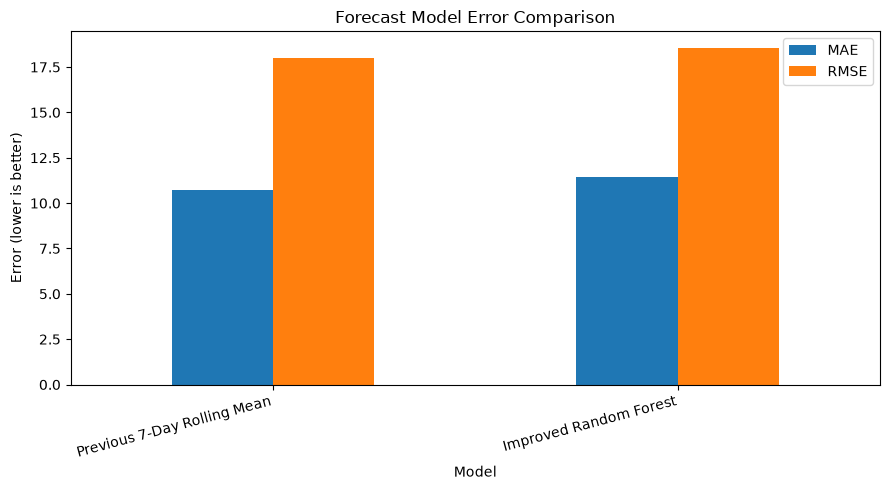

STEP 22 - FORECAST MODEL COMPARISON
                      Model    MAE   RMSE
Previous 7-Day Rolling Mean 10.700 18.000
     Improved Random Forest 11.464 18.541

CSV saved to: C:\Users\admin\OneDrive\Desktop\Activity-2\output\time_series_results\step_22_model_comparison.csv
Chart saved to: C:\Users\admin\OneDrive\Desktop\Activity-2\output\time_series_results\step_22_model_comparison.png

STEP 22 COMPLETED SUCCESSFULLY


In [89]:
# ============================================================
# STEP 22 - FORECAST MODEL COMPARISON
# ============================================================

import os
import pandas as pd
import matplotlib.pyplot as plt

folder = r"C:\Users\admin\OneDrive\Desktop\Activity-2\output\time_series_results"

baseline = pd.read_csv(os.path.join(folder, "step_20_baseline_metrics.csv"))
random_forest = pd.read_csv(os.path.join(folder, "step_21_random_forest_metrics.csv"))

comparison = pd.concat([
    baseline[["Model", "MAE", "RMSE"]],
    random_forest[["Model", "MAE", "RMSE"]]
], ignore_index=True)

csv_file = os.path.join(folder, "step_22_model_comparison.csv")
chart_file = os.path.join(folder, "step_22_model_comparison.png")

comparison.to_csv(csv_file, index=False)

comparison.set_index("Model")[["MAE", "RMSE"]].plot(kind="bar", figsize=(9, 5))
plt.title("Forecast Model Error Comparison")
plt.ylabel("Error (lower is better)")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.savefig(chart_file, dpi=150)
plt.show()

print("=" * 65)
print("STEP 22 - FORECAST MODEL COMPARISON")
print("=" * 65)
print(comparison.to_string(index=False))
print("\nCSV saved to:", os.path.abspath(csv_file))
print("Chart saved to:", os.path.abspath(chart_file))
print("\nSTEP 22 COMPLETED SUCCESSFULLY")

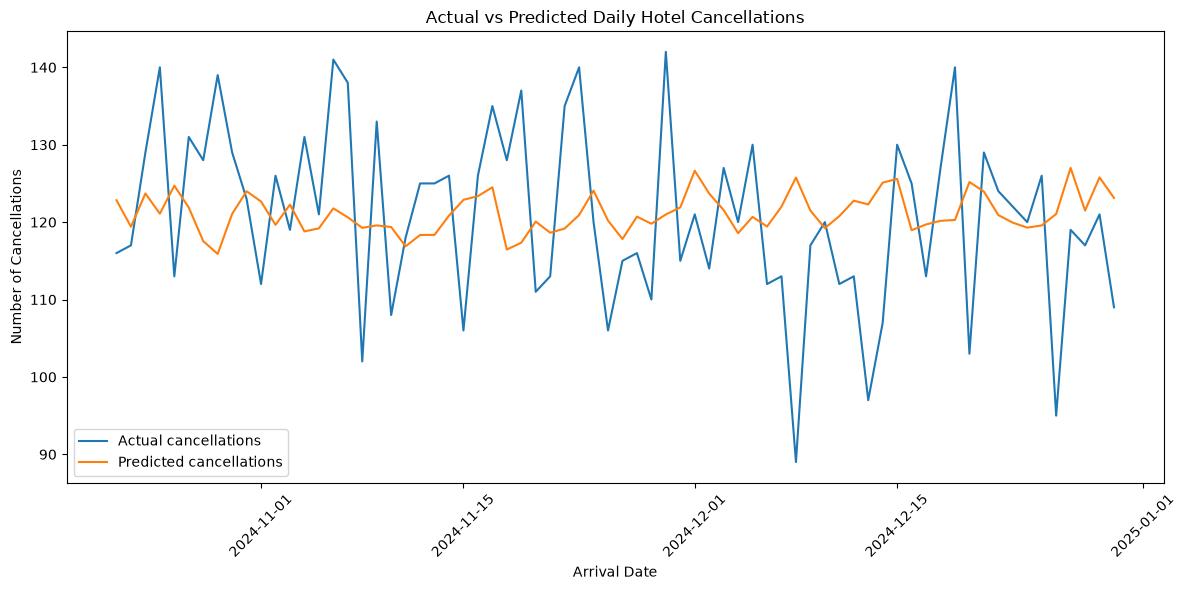

STEP 23 - CORRECTED ACTUAL VS PREDICTED CANCELLATIONS
Bookings on original final date: 2
Final date excluded: True
Test dates plotted: 70
Chart saved to: C:\Users\admin\OneDrive\Desktop\Activity-2\output\time_series_results\step_23_actual_vs_predicted.png

STEP 23 COMPLETED SUCCESSFULLY


In [90]:
# ============================================================
# STEP 23 - CORRECTED ACTUAL VS PREDICTED CANCELLATIONS
# ============================================================

import os
import pandas as pd
import matplotlib.pyplot as plt

folder = r"C:\Users\admin\OneDrive\Desktop\Activity-2\output\time_series_results"

# Load Step 21 predictions
prediction_file = os.path.join(
    folder, "step_21_random_forest_predictions.csv"
)
predictions = pd.read_csv(
    prediction_file, parse_dates=["arrival_date"]
)

# Load original booking data to identify the incomplete final date
dataset_path = r"C:\Users\admin\OneDrive\Desktop\Activity-2\output\preprocessing_results\hotel_bookings_cleaned.csv"
bookings = pd.read_csv(dataset_path)

bookings["arrival_date"] = pd.to_datetime(
    bookings["arrival_date"], errors="coerce"
)
bookings = bookings.dropna(subset=["arrival_date"])

last_date = bookings["arrival_date"].max()
last_date_count = int(
    (bookings["arrival_date"] == last_date).sum()
)

# Exclude the incomplete final date from the comparison if needed
if last_date_count < 10:
    predictions = predictions[
        predictions["arrival_date"] < last_date
    ].copy()

# Plot actual vs predicted values
chart_file = os.path.join(
    folder, "step_23_actual_vs_predicted.png"
)

plt.figure(figsize=(12, 6))
plt.plot(
    predictions["arrival_date"],
    predictions["Actual_Cancellations"],
    label="Actual cancellations"
)
plt.plot(
    predictions["arrival_date"],
    predictions["Predicted_Cancellations"],
    label="Predicted cancellations"
)

plt.title("Actual vs Predicted Daily Hotel Cancellations")
plt.xlabel("Arrival Date")
plt.ylabel("Number of Cancellations")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(chart_file, dpi=150)
plt.show()

print("=" * 65)
print("STEP 23 - CORRECTED ACTUAL VS PREDICTED CANCELLATIONS")
print("=" * 65)
print("Bookings on original final date:", last_date_count)
print("Final date excluded:", last_date_count < 10)
print("Test dates plotted:", len(predictions))
print("Chart saved to:", os.path.abspath(chart_file))
print("\nSTEP 23 COMPLETED SUCCESSFULLY")

In [91]:
# ============================================================
# STEP 24 - NEXT 30-DAY CANCELLATION FORECAST
# ============================================================

import os
import pandas as pd
import numpy as np
import joblib

folder = r"C:\Users\admin\OneDrive\Desktop\Activity-2\output\time_series_results"

data = pd.read_csv(os.path.join(folder, "step_17_forecasting_dataset.csv"))
data["arrival_date"] = pd.to_datetime(data["arrival_date"], errors="coerce")
data = data.sort_values("arrival_date")

model_file = os.path.join(folder, "step_21_cancellation_forecast_model.pkl")
model = joblib.load(model_file)

history = data["Cancellations"].astype(float).tolist()
last_date = data["arrival_date"].max()

future_rows = []

for step in range(1, 31):
    future_date = last_date + pd.Timedelta(days=step)

    X_next = pd.DataFrame([{
        "Lag_1": history[-1],
        "Lag_7": history[-7],
        "Lag_14": history[-14],
        "Rolling_Mean_7": float(np.mean(history[-7:])),
        "Day_Of_Week": future_date.dayofweek
    }])

    predicted = max(0.0, float(model.predict(X_next)[0]))

    future_rows.append({
        "Forecast_Date": future_date,
        "Predicted_Cancellations": round(predicted, 2)
    })

    history.append(predicted)

forecast = pd.DataFrame(future_rows)
output_file = os.path.join(folder, "step_24_next_30_day_forecast.csv")
forecast.to_csv(output_file, index=False)

print("=" * 65)
print("STEP 24 - NEXT 30-DAY CANCELLATION FORECAST")
print("=" * 65)
print(forecast.to_string(index=False))
print("\nForecast saved to:", os.path.abspath(output_file))
print("NOTE: This is an exploratory forecast based on one year of data.")
print("\nSTEP 24 COMPLETED SUCCESSFULLY")

STEP 24 - NEXT 30-DAY CANCELLATION FORECAST
Forecast_Date  Predicted_Cancellations
   2025-01-01                   121.83
   2025-01-02                   122.26
   2025-01-03                   120.77
   2025-01-04                   121.94
   2025-01-05                   123.70
   2025-01-06                   120.19
   2025-01-07                   120.97
   2025-01-08                   118.85
   2025-01-09                   118.03
   2025-01-10                   121.07
   2025-01-11                   121.37
   2025-01-12                   122.76
   2025-01-13                   117.19
   2025-01-14                   118.55
   2025-01-15                   121.04
   2025-01-16                   119.98
   2025-01-17                   120.46
   2025-01-18                   120.15
   2025-01-19                   122.64
   2025-01-20                   121.36
   2025-01-21                   119.93
   2025-01-22                   120.67
   2025-01-23                   121.67
   2025-01-24       

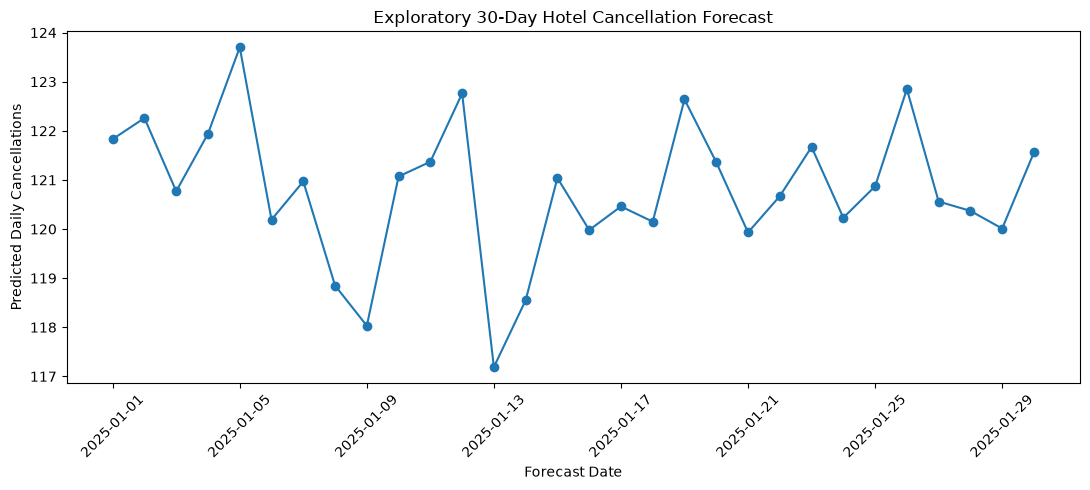

STEP 25 - FORECAST VISUALIZATION AND SUMMARY
 Forecast_Days Forecast_Start Forecast_End  Mean_Daily_Forecast  Minimum_Daily_Forecast  Maximum_Daily_Forecast                                               Limitation
            30     2025-01-01   2025-01-30               120.79                  117.19                   123.7 Exploratory forecast trained on one year of booking data

Chart saved to: C:\Users\admin\OneDrive\Desktop\Activity-2\output\time_series_results\step_25_30_day_forecast_chart.png
Summary saved to: C:\Users\admin\OneDrive\Desktop\Activity-2\output\time_series_results\step_25_forecast_summary.csv

STEP 25 COMPLETED SUCCESSFULLY


In [92]:
# ============================================================
# STEP 25 - FORECAST VISUALIZATION AND SUMMARY
# ============================================================

import os
import pandas as pd
import matplotlib.pyplot as plt

folder = r"C:\Users\admin\OneDrive\Desktop\Activity-2\output\time_series_results"

input_file = os.path.join(folder, "step_24_next_30_day_forecast.csv")
forecast = pd.read_csv(input_file)
forecast["Forecast_Date"] = pd.to_datetime(forecast["Forecast_Date"])

chart_file = os.path.join(folder, "step_25_30_day_forecast_chart.png")
summary_file = os.path.join(folder, "step_25_forecast_summary.csv")

plt.figure(figsize=(11, 5))
plt.plot(
    forecast["Forecast_Date"],
    forecast["Predicted_Cancellations"],
    marker="o"
)
plt.title("Exploratory 30-Day Hotel Cancellation Forecast")
plt.xlabel("Forecast Date")
plt.ylabel("Predicted Daily Cancellations")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(chart_file, dpi=150)
plt.show()

summary = pd.DataFrame([{
    "Forecast_Days": len(forecast),
    "Forecast_Start": forecast["Forecast_Date"].min().date(),
    "Forecast_End": forecast["Forecast_Date"].max().date(),
    "Mean_Daily_Forecast": round(forecast["Predicted_Cancellations"].mean(), 2),
    "Minimum_Daily_Forecast": round(forecast["Predicted_Cancellations"].min(), 2),
    "Maximum_Daily_Forecast": round(forecast["Predicted_Cancellations"].max(), 2),
    "Limitation": "Exploratory forecast trained on one year of booking data"
}])

summary.to_csv(summary_file, index=False)

print("=" * 65)
print("STEP 25 - FORECAST VISUALIZATION AND SUMMARY")
print("=" * 65)
print(summary.to_string(index=False))
print("\nChart saved to:", os.path.abspath(chart_file))
print("Summary saved to:", os.path.abspath(summary_file))
print("\nSTEP 25 COMPLETED SUCCESSFULLY")

STEP 26 - FINAL FORECAST EVALUATION SUMMARY

Baseline metrics:
                      Model  Test_Rows  MAE  RMSE
Previous 7-Day Rolling Mean         71 10.7  18.0

Random Forest metrics:
                 Model  Test_Rows    MAE   RMSE     R2
Improved Random Forest         71 11.464 18.541 -0.036


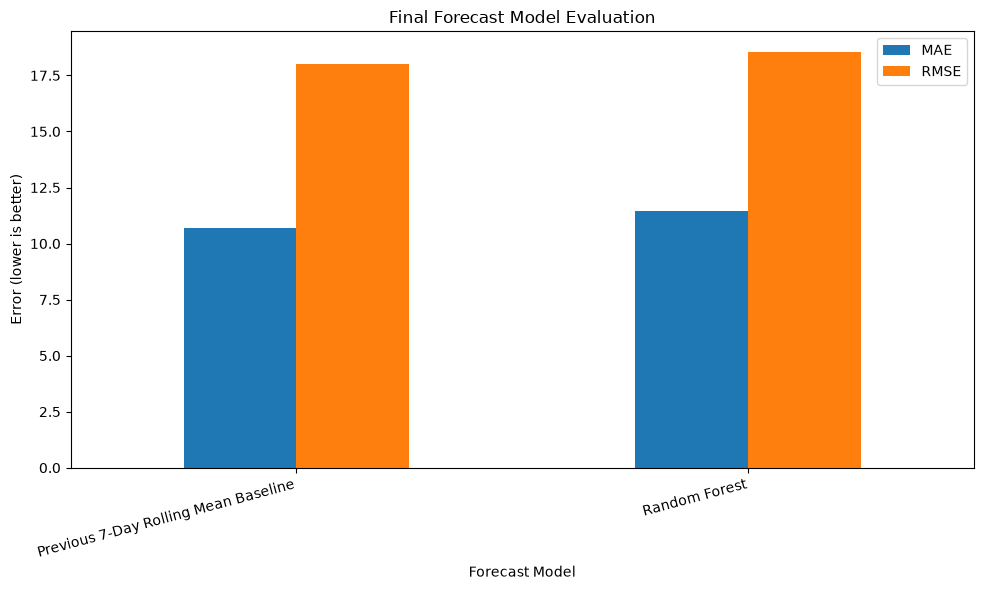


Model comparison:
                               Model    MAE   RMSE
Previous 7-Day Rolling Mean Baseline 10.700 18.000
                       Random Forest 11.464 18.541

Preferred model: Previous 7-Day Rolling Mean Baseline
Conclusion: The baseline performed better on both MAE and RMSE.

Comparison CSV saved to: C:\Users\admin\OneDrive\Desktop\Activity-2\output\time_series_results\step_26_final_forecast_evaluation.csv
Chart saved to: C:\Users\admin\OneDrive\Desktop\Activity-2\output\time_series_results\step_26_final_forecast_evaluation.png
Findings saved to: C:\Users\admin\OneDrive\Desktop\Activity-2\output\time_series_results\step_26_forecast_findings_summary.csv

STEP 26 COMPLETED SUCCESSFULLY


In [93]:
# ============================================================
# STEP 26 - FINAL FORECAST EVALUATION SUMMARY
# ============================================================

import os
import pandas as pd
import matplotlib.pyplot as plt

# Output folder
folder = r"C:\Users\admin\OneDrive\Desktop\Activity-2\output\time_series_results"
os.makedirs(folder, exist_ok=True)

# Step 20 and Step 21 metrics files
baseline_file = os.path.join(folder, "step_20_baseline_metrics.csv")
random_forest_file = os.path.join(folder, "step_21_random_forest_metrics.csv")

# Check that both files exist
if not os.path.exists(baseline_file):
    raise FileNotFoundError("Step 20 baseline metrics file was not found.")

if not os.path.exists(random_forest_file):
    raise FileNotFoundError("Step 21 Random Forest metrics file was not found.")

# Load metrics
baseline = pd.read_csv(baseline_file)
random_forest = pd.read_csv(random_forest_file)

# Display source metrics for verification
print("=" * 65)
print("STEP 26 - FINAL FORECAST EVALUATION SUMMARY")
print("=" * 65)

print("\nBaseline metrics:")
print(baseline.to_string(index=False))

print("\nRandom Forest metrics:")
print(random_forest.to_string(index=False))

# Extract metrics
baseline_row = baseline.iloc[0]
rf_row = random_forest.iloc[0]

baseline_mae = float(baseline_row["MAE"])
baseline_rmse = float(baseline_row["RMSE"])

rf_mae = float(rf_row["MAE"])
rf_rmse = float(rf_row["RMSE"])

# Lower MAE and RMSE indicate better performance
if rf_mae < baseline_mae and rf_rmse < baseline_rmse:
    best_model = "Random Forest"
    conclusion = "Random Forest performed better on both MAE and RMSE."
elif baseline_mae < rf_mae and baseline_rmse < rf_rmse:
    best_model = "Previous 7-Day Rolling Mean Baseline"
    conclusion = "The baseline performed better on both MAE and RMSE."
else:
    best_model = "Mixed results"
    conclusion = "Each model performed better on at least one metric."

# Build comparison table
comparison = pd.DataFrame({
    "Model": [
        "Previous 7-Day Rolling Mean Baseline",
        "Random Forest"
    ],
    "MAE": [baseline_mae, rf_mae],
    "RMSE": [baseline_rmse, rf_rmse]
})

comparison["MAE"] = comparison["MAE"].round(3)
comparison["RMSE"] = comparison["RMSE"].round(3)

# Save comparison CSV
csv_path = os.path.join(
    folder, "step_26_final_forecast_evaluation.csv"
)
comparison.to_csv(csv_path, index=False)

# Create comparison chart
chart_path = os.path.join(
    folder, "step_26_final_forecast_evaluation.png"
)

ax = comparison.set_index("Model")[["MAE", "RMSE"]].plot(
    kind="bar", figsize=(10, 6)
)

ax.set_title("Final Forecast Model Evaluation")
ax.set_xlabel("Forecast Model")
ax.set_ylabel("Error (lower is better)")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.savefig(chart_path, dpi=150)
plt.show()

# Save findings summary
summary = pd.DataFrame([{
    "Step": 26,
    "Baseline_MAE": baseline_mae,
    "Baseline_RMSE": baseline_rmse,
    "Random_Forest_MAE": rf_mae,
    "Random_Forest_RMSE": rf_rmse,
    "Preferred_Model": best_model,
    "Conclusion": conclusion,
    "Data_Limitation": (
        "Only one year of observations; forecast is exploratory."
    )
}])

summary_path = os.path.join(
    folder, "step_26_forecast_findings_summary.csv"
)
summary.to_csv(summary_path, index=False)

print("\nModel comparison:")
print(comparison.to_string(index=False))
print("\nPreferred model:", best_model)
print("Conclusion:", conclusion)
print("\nComparison CSV saved to:", os.path.abspath(csv_path))
print("Chart saved to:", os.path.abspath(chart_path))
print("Findings saved to:", os.path.abspath(summary_path))
print("\nSTEP 26 COMPLETED SUCCESSFULLY")

In [94]:
# ============================================================
# STEP 27 - FORECAST ACCURACY INTERPRETATION
# ============================================================

import os
import pandas as pd

# Output folder
folder = r"C:\Users\admin\OneDrive\Desktop\Activity-2\output\time_series_results"
os.makedirs(folder, exist_ok=True)

# Load Step 26 results
input_file = os.path.join(
    folder, "step_26_final_forecast_evaluation.csv"
)

if not os.path.exists(input_file):
    raise FileNotFoundError(
        "Step 26 results not found. Run Step 26 first."
    )

comparison = pd.read_csv(input_file)

print("=" * 65)
print("STEP 27 - FORECAST ACCURACY INTERPRETATION")
print("=" * 65)

print("\nModel metrics:")
print(comparison.to_string(index=False))

# Identify baseline and Random Forest
baseline = comparison[
    comparison["Model"].str.contains("Baseline", case=False)
].iloc[0]

rf = comparison[
    comparison["Model"].str.contains("Random Forest", case=False)
].iloc[0]

# Calculate percentage differences relative to baseline
mae_difference = rf["MAE"] - baseline["MAE"]
rmse_difference = rf["RMSE"] - baseline["RMSE"]

mae_difference_pct = (
    mae_difference / baseline["MAE"] * 100
    if baseline["MAE"] != 0 else float("nan")
)

rmse_difference_pct = (
    rmse_difference / baseline["RMSE"] * 100
    if baseline["RMSE"] != 0 else float("nan")
)

if rf["MAE"] < baseline["MAE"] and rf["RMSE"] < baseline["RMSE"]:
    conclusion = (
        "Random Forest outperformed the baseline on both error metrics."
    )
elif rf["MAE"] > baseline["MAE"] and rf["RMSE"] > baseline["RMSE"]:
    conclusion = (
        "The baseline outperformed Random Forest on both error metrics."
    )
else:
    conclusion = (
        "The models had mixed results across the error metrics."
    )

findings = pd.DataFrame([{
    "Baseline_MAE": baseline["MAE"],
    "Random_Forest_MAE": rf["MAE"],
    "MAE_Difference": round(mae_difference, 3),
    "MAE_Difference_Percent": round(mae_difference_pct, 2),
    "Baseline_RMSE": baseline["RMSE"],
    "Random_Forest_RMSE": rf["RMSE"],
    "RMSE_Difference": round(rmse_difference, 3),
    "RMSE_Difference_Percent": round(rmse_difference_pct, 2),
    "Conclusion": conclusion,
    "Limitation": (
        "The dataset contains only one year of observations; "
        "results and future forecasts are exploratory."
    )
}])

output_file = os.path.join(
    folder, "step_27_forecast_accuracy_interpretation.csv"
)

findings.to_csv(output_file, index=False)

print("\nMAE difference:", round(mae_difference, 3))
print("MAE difference (%):", round(mae_difference_pct, 2))
print("RMSE difference:", round(rmse_difference, 3))
print("RMSE difference (%):", round(rmse_difference_pct, 2))
print("\nConclusion:", conclusion)
print("\nSaved to:", os.path.abspath(output_file))
print("\nSTEP 27 COMPLETED SUCCESSFULLY")

STEP 27 - FORECAST ACCURACY INTERPRETATION

Model metrics:
                               Model    MAE   RMSE
Previous 7-Day Rolling Mean Baseline 10.700 18.000
                       Random Forest 11.464 18.541

MAE difference: 0.764
MAE difference (%): 7.14
RMSE difference: 0.541
RMSE difference (%): 3.01

Conclusion: The baseline outperformed Random Forest on both error metrics.

Saved to: C:\Users\admin\OneDrive\Desktop\Activity-2\output\time_series_results\step_27_forecast_accuracy_interpretation.csv

STEP 27 COMPLETED SUCCESSFULLY


In [95]:
# ============================================================
# STEP 28 - FINAL TIME-SERIES RESULTS SUMMARY
# ============================================================

import os
import pandas as pd

# Output folder
folder = r"C:\Users\admin\OneDrive\Desktop\Activity-2\output\time_series_results"
os.makedirs(folder, exist_ok=True)

# Files generated by previous steps
required_files = {
    "Daily Trends": "step_04_daily_cancellation_trends.csv",
    "Monthly Trends": "step_05_monthly_cancellation_trends.csv",
    "Quarterly Analysis": "step_14_quarterly_cancellation_analysis.csv",
    "Baseline Metrics": "step_20_baseline_metrics.csv",
    "Random Forest Metrics": "step_21_random_forest_metrics.csv",
    "Model Comparison": "step_26_final_forecast_evaluation.csv",
    "Accuracy Interpretation": "step_27_forecast_accuracy_interpretation.csv",
    "30-Day Forecast": "step_24_next_30_day_forecast.csv",
    "Forecast Summary": "step_25_forecast_summary.csv"
}

print("=" * 65)
print("STEP 28 - FINAL TIME-SERIES RESULTS SUMMARY")
print("=" * 65)

# Validate files
validation = []

for description, filename in required_files.items():
    filepath = os.path.join(folder, filename)
    validation.append({
        "Item": description,
        "File": filename,
        "Exists": os.path.exists(filepath)
    })

validation_df = pd.DataFrame(validation)
print("\nRequired file validation:")
print(validation_df.to_string(index=False))

missing = validation_df[~validation_df["Exists"]]

if not missing.empty:
    print("\nSome files are missing. Check the filenames and run the relevant steps.")
    print(missing[["Item", "File"]].to_string(index=False))
    raise FileNotFoundError(
        "Step 28 stopped because one or more required files are missing."
    )

# Read model comparison and forecast
comparison = pd.read_csv(
    os.path.join(folder, required_files["Model Comparison"])
)

forecast = pd.read_csv(
    os.path.join(folder, required_files["30-Day Forecast"])
)

interpretation = pd.read_csv(
    os.path.join(folder, required_files["Accuracy Interpretation"])
)

# Determine preferred model from saved evaluation
preferred_model = str(interpretation.iloc[0]["Conclusion"])

forecast_column = "Predicted_Cancellations"

if forecast_column in forecast.columns:
    forecast_values = pd.to_numeric(
        forecast[forecast_column], errors="coerce"
    ).dropna()

    forecast_mean = round(forecast_values.mean(), 2)
    forecast_min = round(forecast_values.min(), 2)
    forecast_max = round(forecast_values.max(), 2)
else:
    forecast_mean = None
    forecast_min = None
    forecast_max = None

# Build final summary
summary = pd.DataFrame([
    {
        "Category": "Project",
        "Finding": "Activity 2 - Time-Series Analysis"
    },
    {
        "Category": "Dataset",
        "Finding": "Hotel booking data with one year of observations"
    },
    {
        "Category": "Daily Analysis",
        "Finding": "Daily booking and cancellation trends analyzed"
    },
    {
        "Category": "Monthly Analysis",
        "Finding": "Monthly booking volumes and cancellation rates analyzed"
    },
    {
        "Category": "Quarterly Analysis",
        "Finding": "Quarterly cancellation rates analyzed"
    },
    {
        "Category": "Preferred Forecast Model",
        "Finding": preferred_model
    },
    {
        "Category": "Mean 30-Day Forecast",
        "Finding": forecast_mean
    },
    {
        "Category": "Minimum 30-Day Forecast",
        "Finding": forecast_min
    },
    {
        "Category": "Maximum 30-Day Forecast",
        "Finding": forecast_max
    },
    {
        "Category": "Limitation",
        "Finding": (
            "Forecast is exploratory; one year of data is insufficient "
            "to establish reliable long-term seasonal patterns."
        )
    }
])

output_file = os.path.join(
    folder, "step_28_final_time_series_results_summary.csv"
)

summary.to_csv(output_file, index=False)

print("\nFinal summary:")
print(summary.to_string(index=False))
print("\nSummary saved to:", os.path.abspath(output_file))
print("\nSTEP 28 COMPLETED SUCCESSFULLY")

STEP 28 - FINAL TIME-SERIES RESULTS SUMMARY

Required file validation:
                   Item                                         File  Exists
           Daily Trends        step_04_daily_cancellation_trends.csv    True
         Monthly Trends      step_05_monthly_cancellation_trends.csv    True
     Quarterly Analysis  step_14_quarterly_cancellation_analysis.csv    True
       Baseline Metrics                 step_20_baseline_metrics.csv    True
  Random Forest Metrics            step_21_random_forest_metrics.csv    True
       Model Comparison        step_26_final_forecast_evaluation.csv    True
Accuracy Interpretation step_27_forecast_accuracy_interpretation.csv    True
        30-Day Forecast             step_24_next_30_day_forecast.csv    True
       Forecast Summary                 step_25_forecast_summary.csv    True

Final summary:
                Category                                                                                                      Finding
         

In [96]:
# ============================================================
# STEP 29 - FINAL TIME-SERIES OUTPUT VALIDATION
# ============================================================

import os
import pandas as pd

# Output folder
folder = r"C:\Users\admin\OneDrive\Desktop\Activity-2\output\time_series_results"
os.makedirs(folder, exist_ok=True)

# Important outputs to validate
required_files = [
    "step_01_time_series_project_setup.csv",
    "step_02_time_series_data_quality.csv",
    "step_03_time_series_prepared_data.csv",
    "step_04_daily_cancellation_trends.csv",
    "step_05_monthly_cancellation_trends.csv",
    "step_06_daily_cancellations_chart.png",
    "step_07_monthly_volume_chart.png",
    "step_08_hotel_type_cancellation_summary.csv",
    "step_09_weekday_cancellation_summary.csv",
    "step_10_month_of_year_cancellation_summary.csv",
    "step_11_daily_moving_average.csv",
    "step_12_daily_chart_quality_summary.csv",
    "step_13_weekly_cancellation_analysis.csv",
    "step_14_quarterly_cancellation_analysis.csv",
    "step_15_decomposition_components.csv",
    "step_16_stationarity_test.csv",
    "step_17_forecasting_dataset.csv",
    "step_18_lag_features.csv",
    "step_19_train_data.csv",
    "step_19_test_data.csv",
    "step_20_baseline_metrics.csv",
    "step_21_random_forest_metrics.csv",
    "step_22_model_comparison.csv",
    "step_23_actual_vs_predicted.png",
    "step_24_next_30_day_forecast.csv",
    "step_25_forecast_summary.csv",
    "step_26_final_forecast_evaluation.csv",
    "step_27_forecast_accuracy_interpretation.csv",
    "step_28_final_time_series_results_summary.csv"
]

# Validate files and sizes
results = []

for filename in required_files:
    filepath = os.path.join(folder, filename)

    results.append({
        "File": filename,
        "Exists": os.path.isfile(filepath),
        "Size_KB": (
            round(os.path.getsize(filepath) / 1024, 2)
            if os.path.isfile(filepath) else None
        )
    })

validation_df = pd.DataFrame(results)

# Save validation report
output_file = os.path.join(
    folder, "step_29_final_time_series_output_validation.csv"
)
validation_df.to_csv(output_file, index=False)

# Display results
missing = validation_df[~validation_df["Exists"]]

print("=" * 65)
print("STEP 29 - FINAL TIME-SERIES OUTPUT VALIDATION")
print("=" * 65)

print(validation_df.to_string(index=False))
print("\nTotal files checked:", len(validation_df))
print("Files found:", int(validation_df["Exists"].sum()))
print("Missing files:", len(missing))

if not missing.empty:
    print("\nFiles requiring attention:")
    print(missing["File"].to_string(index=False))
else:
    print("\nAll listed files are present.")

print("\nValidation report saved to:", os.path.abspath(output_file))
print("\nSTEP 29 COMPLETED SUCCESSFULLY")

STEP 29 - FINAL TIME-SERIES OUTPUT VALIDATION
                                          File  Exists  Size_KB
         step_01_time_series_project_setup.csv    True     0.43
          step_02_time_series_data_quality.csv    True     0.28
         step_03_time_series_prepared_data.csv    True 26467.94
         step_04_daily_cancellation_trends.csv    True    10.75
       step_05_monthly_cancellation_trends.csv    True     0.47
         step_06_daily_cancellations_chart.png    True   143.87
              step_07_monthly_volume_chart.png    True    60.25
   step_08_hotel_type_cancellation_summary.csv    True     0.13
      step_09_weekday_cancellation_summary.csv    True     0.24
step_10_month_of_year_cancellation_summary.csv    True     0.39
              step_11_daily_moving_average.csv    True    27.54
       step_12_daily_chart_quality_summary.csv    True     0.39
      step_13_weekly_cancellation_analysis.csv    True     1.73
   step_14_quarterly_cancellation_analysis.csv    True    

In [97]:
# ============================================================
# STEP 30 - FINAL TIME-SERIES FINDINGS REPORT
# ============================================================

import os
import pandas as pd
from datetime import datetime

# Output folder
folder = r"C:\Users\admin\OneDrive\Desktop\Activity-2\output\time_series_results"
os.makedirs(folder, exist_ok=True)

# Input files
monthly_file = os.path.join(
    folder, "step_05_monthly_cancellation_trends.csv"
)
quarterly_file = os.path.join(
    folder, "step_14_quarterly_cancellation_analysis.csv"
)
comparison_file = os.path.join(
    folder, "step_26_final_forecast_evaluation.csv"
)
forecast_file = os.path.join(
    folder, "step_24_next_30_day_forecast.csv"
)
interpretation_file = os.path.join(
    folder, "step_27_forecast_accuracy_interpretation.csv"
)

required_inputs = [
    monthly_file,
    quarterly_file,
    comparison_file,
    forecast_file,
    interpretation_file
]

missing_inputs = [
    path for path in required_inputs
    if not os.path.isfile(path)
]

if missing_inputs:
    raise FileNotFoundError(
        "Required input file(s) missing:\n" + "\n".join(missing_inputs)
    )

# Load results
monthly = pd.read_csv(monthly_file)
quarterly = pd.read_csv(quarterly_file)
comparison = pd.read_csv(comparison_file)
forecast = pd.read_csv(forecast_file)
interpretation = pd.read_csv(interpretation_file)

# Read model metrics
baseline = comparison[
    comparison["Model"].str.contains("Baseline", case=False)
].iloc[0]

rf = comparison[
    comparison["Model"].str.contains("Random Forest", case=False)
].iloc[0]

finding = interpretation.iloc[0]

# Read forecast values
forecast_col = "Predicted_Cancellations"
forecast_values = pd.to_numeric(
    forecast[forecast_col], errors="coerce"
).dropna()

mean_forecast = forecast_values.mean()
min_forecast = forecast_values.min()
max_forecast = forecast_values.max()

# Determine highest and lowest monthly cancellation rates
rate_col = "Cancellation_Rate_Percent"

highest_month = monthly.loc[monthly[rate_col].idxmax()]
lowest_month = monthly.loc[monthly[rate_col].idxmin()]

# Build report
report_lines = [
    "=" * 75,
    "FINAL TIME-SERIES HOTEL CANCELLATION ANALYSIS REPORT",
    "=" * 75,
    "",
    "Project: Hotel Booking Cancellation Prediction and Analysis",
    "Stage: Activity 2 - Time-Series Analysis",
    "Report generated: " + datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
    "",
    "1. OBJECTIVE",
    "Analyze booking cancellations over time, explore daily, weekly,",
    "monthly and quarterly patterns, and evaluate an exploratory forecast.",
    "",
    "2. DATASET",
    "Total booking records: 119,390 (as reported during setup).",
    "The arrival-date data covers 2024 only.",
    "",
    "3. MONTHLY CANCELLATION PATTERNS",
    "Highest monthly cancellation rate: "
    + str(highest_month.iloc[0])
    + " (" + str(round(highest_month[rate_col], 2)) + "%).",
    "Lowest monthly cancellation rate: "
    + str(lowest_month.iloc[0])
    + " (" + str(round(lowest_month[rate_col], 2)) + "%).",
    "",
    "4. QUARTERLY ANALYSIS",
    quarterly.to_string(index=False),
    "",
    "5. FORECAST MODEL EVALUATION",
    "Baseline model: Previous 7-Day Rolling Mean",
    "Baseline MAE: " + str(round(baseline["MAE"], 3)),
    "Baseline RMSE: " + str(round(baseline["RMSE"], 3)),
    "Random Forest MAE: " + str(round(rf["MAE"], 3)),
    "Random Forest RMSE: " + str(round(rf["RMSE"], 3)),
    "Conclusion: " + str(finding["Conclusion"]),
    "",
    "6. EXPLORATORY 30-DAY FORECAST",
    "Mean predicted daily cancellations: " + str(round(mean_forecast, 2)),
    "Minimum predicted daily cancellations: " + str(round(min_forecast, 2)),
    "Maximum predicted daily cancellations: " + str(round(max_forecast, 2)),
    "",
    "7. LIMITATIONS",
    "- Only one year of booking data is available.",
    "- Long-term and multi-year seasonal patterns cannot be established.",
    "- The Random Forest did not outperform the baseline on MAE or RMSE.",
    "- Forecast values should not be treated as reliable operational targets.",
    "- The original final date had only two bookings and was excluded from",
    "  the corrected daily and weekly charts where applicable.",
    "",
    "8. CONCLUSION",
    "The analysis summarizes cancellation patterns across multiple time",
    "periods. The rolling-mean baseline performed better than the tested",
    "Random Forest model. The 30-day forecast is exploratory and should",
    "be interpreted cautiously because the dataset covers only one year.",
    "",
    "=" * 75
]

report_text = "\n".join(report_lines)

# Save report
report_file = os.path.join(
    folder, "step_30_final_time_series_analysis_report.txt"
)

with open(report_file, "w", encoding="utf-8") as file:
    file.write(report_text)

print(report_text)
print("\nReport saved to:", os.path.abspath(report_file))
print("\nSTEP 30 COMPLETED SUCCESSFULLY")

FINAL TIME-SERIES HOTEL CANCELLATION ANALYSIS REPORT

Project: Hotel Booking Cancellation Prediction and Analysis
Stage: Activity 2 - Time-Series Analysis
Report generated: 2026-10-23 23:00:52

1. OBJECTIVE
Analyze booking cancellations over time, explore daily, weekly,
monthly and quarterly patterns, and evaluate an exploratory forecast.

2. DATASET
Total booking records: 119,390 (as reported during setup).
The arrival-date data covers 2024 only.

3. MONTHLY CANCELLATION PATTERNS
Highest monthly cancellation rate: 2024-11-01 (37.95%).
Lowest monthly cancellation rate: 2024-03-01 (36.53%).

4. QUARTERLY ANALYSIS
Quarter  Total_Bookings  Cancellations  Not_Canceled  Cancellation_Rate_Percent
 2024Q1           29893          11064         18829                      37.01
 2024Q2           29780          11039         18741                      37.07
 2024Q3           30090          11083         19007                      36.83
 2024Q4           29625          11038         18587        

In [98]:
# ============================================================
# STEP 31 - FINAL TIME-SERIES COMPLETION SUMMARY
# ============================================================

import os
import pandas as pd
from datetime import datetime

folder = r"C:\Users\admin\OneDrive\Desktop\Activity-2\output\time_series_results"
os.makedirs(folder, exist_ok=True)

report_file = os.path.join(
    folder, "step_30_final_time_series_analysis_report.txt"
)
validation_file = os.path.join(
    folder, "step_29_final_time_series_output_validation.csv"
)
comparison_file = os.path.join(
    folder, "step_26_final_forecast_evaluation.csv"
)
forecast_file = os.path.join(
    folder, "step_24_next_30_day_forecast.csv"
)

# Validate key inputs
required_inputs = [
    report_file,
    validation_file,
    comparison_file,
    forecast_file
]

missing_inputs = [
    path for path in required_inputs
    if not os.path.isfile(path)
]

if missing_inputs:
    raise FileNotFoundError(
        "Required file(s) missing:\n" + "\n".join(missing_inputs)
    )

# Load results
validation = pd.read_csv(validation_file)
comparison = pd.read_csv(comparison_file)
forecast = pd.read_csv(forecast_file)

baseline = comparison[
    comparison["Model"].str.contains("Baseline", case=False)
].iloc[0]

rf = comparison[
    comparison["Model"].str.contains("Random Forest", case=False)
].iloc[0]

forecast_values = pd.to_numeric(
    forecast["Predicted_Cancellations"], errors="coerce"
).dropna()

# Completion summary
summary = pd.DataFrame([
    ["Project", "Hotel Booking Cancellation Prediction and Analysis"],
    ["Stage", "Activity 2 - Time-Series Analysis"],
    ["Report_Created", os.path.exists(report_file)],
    ["Output_Files_Checked", len(validation)],
    ["Output_Files_Missing", int((~validation["Exists"]).sum())],
    ["Baseline_MAE", round(float(baseline["MAE"]), 3)],
    ["Baseline_RMSE", round(float(baseline["RMSE"]), 3)],
    ["Random_Forest_MAE", round(float(rf["MAE"]), 3)],
    ["Random_Forest_RMSE", round(float(rf["RMSE"]), 3)],
    ["Preferred_Model", "Previous 7-Day Rolling Mean Baseline"],
    ["Mean_30_Day_Forecast", round(float(forecast_values.mean()), 2)],
    ["Forecast_Limitation", "Exploratory forecast; only one year of data"],
    ["Status", "Time-series analysis and reporting completed; final review recommended"],
    ["Date", datetime.now().strftime("%Y-%m-%d %H:%M:%S")]
], columns=["Item", "Result"])

output_file = os.path.join(
    folder, "step_31_final_time_series_completion_summary.csv"
)

summary.to_csv(output_file, index=False)

print("=" * 70)
print("STEP 31 - FINAL TIME-SERIES COMPLETION SUMMARY")
print("=" * 70)
print(summary.to_string(index=False))
print("\nSaved to:", os.path.abspath(output_file))
print("\nSTEP 31 COMPLETED SUCCESSFULLY")

STEP 31 - FINAL TIME-SERIES COMPLETION SUMMARY
                Item                                                                 Result
             Project                     Hotel Booking Cancellation Prediction and Analysis
               Stage                                      Activity 2 - Time-Series Analysis
      Report_Created                                                                   True
Output_Files_Checked                                                                     29
Output_Files_Missing                                                                      0
        Baseline_MAE                                                                   10.7
       Baseline_RMSE                                                                   18.0
   Random_Forest_MAE                                                                 11.464
  Random_Forest_RMSE                                                                 18.541
     Preferred_Model             